# 05 — Presentation

Everything shown in the presentation, in slide order, in one place: only the experiments and models kept for the talk.
Same results as `02_results`, `03_predictions` and `04_appendix` (nothing is retrained here; saved results and models
are read), restricted to the presentation's story:

1. **Problem and data**
2. **Protocol** — block split, windows, metric, class imbalance
3. **Input comparison** (ridge fixed) — current timestep → raw window → hand-crafted features
4. **Model comparison** (input fixed) — ridge → kernel ridge → decision tree → random forest → gradient boosting;
   equal-data check; what a tree learns; where it errs
5. **Unseen recordings** — protocol B and comparison with published models
6. **Limits and conclusion**
7. **Model cards** — per model: validation search, confusion matrices (per leg and 16 states), scores

Every figure is saved to `figures/` (`SAVE_FIGS`), so styles can be tuned here and exported for the slides.
Colours, names and the export folder are set once in the setup cell.

## 0. Setup

In [1]:
import sys; sys.path.insert(0, "..")
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from matplotlib.patches import Patch
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from src.data import LEGS, WINDOW, TEST_RECS_B, labels, load_recordings, split, split_b
from src.features import INPUTS, P_Z, V_FOOT

RESULTS, MODELS_DIR = Path("../outputs/results"), Path("../outputs/models")
FIG_DIR = Path("../figures")
SAVE_FIGS = True          # write every figure to figures/<name>.png
FIG_DIR.mkdir(exist_ok=True)
# style of the ML1 assignment plots: serif Computer Modern (matplotlib's bundled cmr10, no LaTeX install needed),
# 14 pt text, 16 pt labels, 18 pt titles, light-grey grid, full box
plt.rcParams.update({"font.family": "serif", "font.serif": ["cmr10"], "mathtext.fontset": "cm",
                     "axes.formatter.use_mathtext": True, "axes.unicode_minus": False,
                     "font.size": 14, "axes.titlesize": 18, "axes.labelsize": 16, "legend.fontsize": 14,
                     "axes.grid": True, "grid.color": "lightgray", "axes.axisbelow": True,
                     "figure.figsize": (10, 6), "figure.dpi": 100, "savefig.dpi": 300})
# one display name per model, used in every table and figure
NAMES = {"majority": "majority baseline", "ridge_current": "ridge, current timestep",
         "ridge_window_log": "ridge, raw window", "ridge_feat_all": "ridge", "krr_feat_all": "kernel ridge",
         "tree_feat_all": "decision tree", "rf_feat_all": "random forest", "gb_feat_all": "gradient boosting",
         "gb_10k_feat_all": "gradient boosting, 10k windows"}

from matplotlib.colors import to_rgb, LinearSegmentedColormap

USE_PALETTE = True    # False: ML1 style (tab20c); True: the custom PALETTE below
VAL_PLOT_3D = False    # model cards: 3-D surface for two-hyperparameter grids (False: annotated 2-D heatmap)

CMAP, TAB20 = plt.get_cmap("tab20c"), plt.get_cmap("tab20")   # tab20c: 5 hues x 4 shades (dark -> light)
# custom palette: any list of hex colours (e.g. from coolors.co)
#            0 navy     1 dark teal 2 teal     3 sage     4 olive    5 yellow   6 apricot  7 sand     8 coral    9 brick    10 blue    11 light blue
PALETTE = ["#264653", "#287271", "#2a9d8f", "#8ab17d", "#babb74", "#e9c46a", "#efb366", "#f4a261", "#ee8959", "#e76f51", "#457b9d", "#a8c8dc"]

def P(i, tint=0.0):
    """PALETTE colour i as RGB; tint in [0, 1] mixes it with white (0 = as is, 1 = white)."""
    rgb = np.array(to_rgb(PALETTE[i]))
    return tuple(rgb + (1 - rgb) * tint)

def rgb(c):
    return tuple(to_rgb(c))

if USE_PALETTE:   # every role is a PALETTE index (+ optional white tint): edit the numbers to remap
    # models: cool colours for the linear / kernel baselines, warm for boosting (the best model); a family shares
    # a colour, lighter tints for weaker variants
    COLORS = {"ridge_current": P(1, 0.6), "ridge_window_log": P(1, 0.3), "ridge_feat_all": P(1),
              "krr_feat_all": P(3), "tree_feat_all": P(5), "rf_feat_all": P(7),
              "gb_feat_all": P(9), "gb_10k_feat_all": P(7)}
    COLORS_LINE = COLORS                                      # lines: same colours as bars
    GREY, LIGHT_GREY, FOOT_SPEED = "#a6a6a6", P(10, 0.70), P(0)  # baselines / papers, true-contact shading, foot speed
    SPLIT_COLORS = {"train": P(11), "val": P(10), "test": P(8)}
    OUTCOME_COLORS = {"contact, correct": P(10), "air, correct": (1, 1, 1), "false contact": P(8), "missed contact": P(4)}
    PROTOCOL_B_COLORS = [P(3), P(5), P(7), P(9)]              # A seen, B unseen, B without pronking, B pronking only
    INPUT_COLORS = [P(6), P(4), P(1)]                  # ridge on: current timestep, raw window, features
    TREE_COLORS = {"air": P(11, 0.3), "contact": P(8, 0.3)}
    ACCENT = P(9)                                             # chosen hyperparameters
    VAL_COLOR = P(10)                                         # validation curves / surfaces / heatmaps, every model
    CM_COLOR = P(10)                                          # confusion matrices (white -> CM_COLOR), every model
else:             # ML1 style: model families share a tab20c hue (ridge blues, kernel ridge purple, trees greens, boosting oranges);
                  # as in ML1, bars use the medium shade of the hue, lines and markers the dark one
    COLORS = {"ridge_current": CMAP(3), "ridge_window_log": CMAP(2), "ridge_feat_all": CMAP(1),
              "krr_feat_all": CMAP(13), "tree_feat_all": CMAP(10), "rf_feat_all": CMAP(9),
              "gb_feat_all": CMAP(5), "gb_10k_feat_all": CMAP(6)}
    COLORS_LINE = {"ridge_current": CMAP(2), "ridge_window_log": CMAP(1), "ridge_feat_all": CMAP(0),
                   "krr_feat_all": CMAP(12), "tree_feat_all": CMAP(9), "rf_feat_all": CMAP(8),
                   "gb_feat_all": CMAP(4), "gb_10k_feat_all": CMAP(5)}
    GREY, LIGHT_GREY, FOOT_SPEED = CMAP(17), CMAP(19), CMAP(8)
    SPLIT_COLORS = {"train": CMAP(1), "val": CMAP(9), "test": CMAP(5)}   # ML1 train / test MSE bars
    OUTCOME_COLORS = {"contact, correct": rgb(CMAP(0)), "air, correct": (1, 1, 1),
                      "false contact": rgb(TAB20(6)), "missed contact": rgb(CMAP(5))}
    PROTOCOL_B_COLORS = [CMAP(0), CMAP(4), CMAP(6), CMAP(16)]
    INPUT_COLORS = [COLORS[m] for m in ("ridge_current", "ridge_window_log", "ridge_feat_all")]
    TREE_COLORS = {"air": CMAP(6), "contact": CMAP(2)}
    ACCENT = plt.get_cmap("tab10")(1)                       # ML1 fit-line orange, drawn over blue data
    VAL_COLOR = CMAP(0)
    CM_COLOR = CMAP(0)
def tint_cmap(c, low=1.0):
    """Colormap from c tinted with white (low: 1 = white, as the tint in P) up to c itself."""
    c = np.array(rgb(c))
    return LinearSegmentedColormap.from_list("tint", [tuple(c + (1 - c) * low), tuple(c)])

CM_CMAP = tint_cmap(CM_COLOR)   # confusion matrices: white (0 %) -> CM_COLOR (100 % of the true class)

def text_color(c):
    """Black or white, whichever reads better on background c."""
    return "white" if np.dot(rgb(c)[:3], (0.299, 0.587, 0.114)) < 0.55 else "black"

def save(fig, name):
    if SAVE_FIGS:
        fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

### Palette

`USE_PALETTE = True` (default) uses the custom hex list `PALETTE` (`P(i)`, or `P(i, tint)` for a lighter variant);
`False` switches to the ML1 style (`tab20c`, `CMAP(i)`; `TAB20(i)` for extra hues). Every figure takes its colours
from the roles set in the setup cell (`COLORS`, `COLORS_LINE`, `SPLIT_COLORS`, `OUTCOME_COLORS`, `PROTOCOL_B_COLORS`,
`INPUT_COLORS`, `TREE_COLORS`, `ACCENT`, `GREY`, `LIGHT_GREY`, `FOOT_SPEED`): change an index there and re-run.
Model cards use one scheme for every model, so they compare directly: `VAL_COLOR` for the validation plots,
`CM_COLOR` for the confusion matrices (white -> `CM_COLOR` over 0-100 % of the true class).

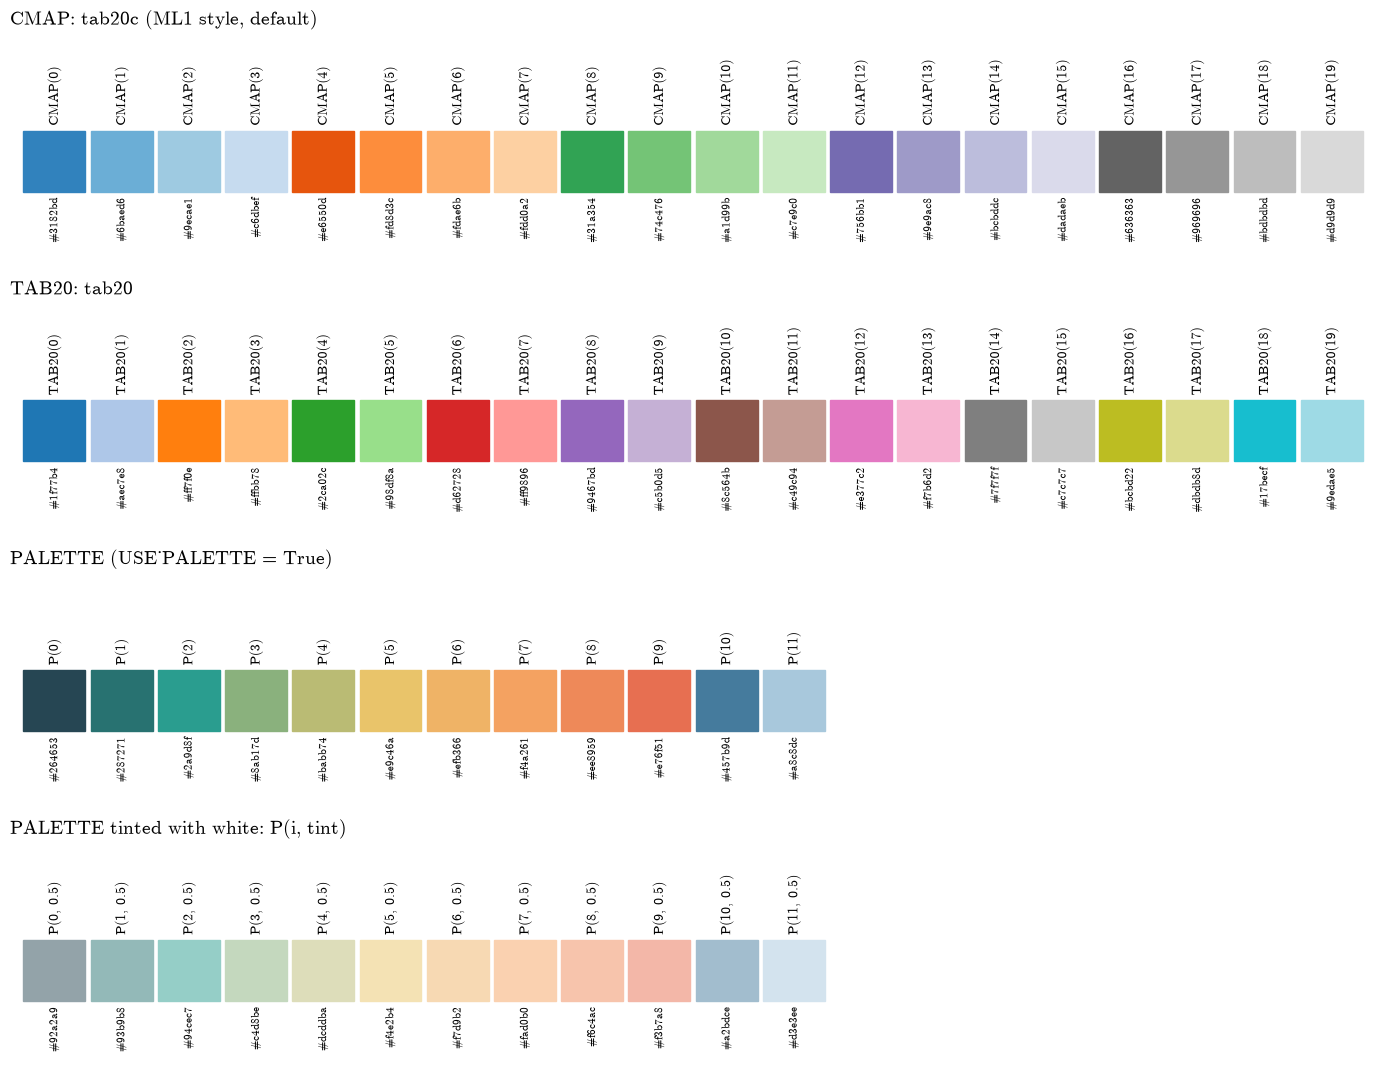

In [2]:
from matplotlib.colors import to_hex

def swatches(ax, colors, labels, title):
    for i, (c, l) in enumerate(zip(colors, labels)):
        ax.add_patch(plt.Rectangle((i, 0), 0.92, 1, color=c))
        ax.text(i + 0.46, 1.08, l, ha="center", va="bottom", fontsize=10, rotation=90)
        ax.text(i + 0.46, -0.1, to_hex(c), ha="center", va="top", fontsize=8, rotation=90)
    ax.set_xlim(-0.2, 20); ax.set_ylim(-1.1, 2.6); ax.axis("off"); ax.set_title(title, fontsize=14, loc="left")

fig, axes = plt.subplots(4, 1, figsize=(14, 11))
swatches(axes[0], [CMAP(i) for i in range(20)], [f"CMAP({i})" for i in range(20)], "CMAP: tab20c (ML1 style, default)")
swatches(axes[1], [TAB20(i) for i in range(20)], [f"TAB20({i})" for i in range(20)], "TAB20: tab20")
swatches(axes[2], [P(i) for i in range(len(PALETTE))], [f"P({i})" for i in range(len(PALETTE))], "PALETTE (USE_PALETTE = True)")
swatches(axes[3], [P(i, 0.5) for i in range(len(PALETTE))], [f"P({i}, 0.5)" for i in range(len(PALETTE))],
         "PALETTE tinted with white: P(i, tint)")
plt.tight_layout(); plt.show()

In [3]:
recs = load_recordings()
sp_a, sp_b = split(recs), split_b(recs)                # protocol A (main) and B (unseen recordings)
y_a, y_b = labels(recs, sp_a["test"]), labels(recs, sp_b["test"])

def load(folder, names):
    """{model: (result json, test predictions)} for the runs saved in outputs/results/<folder>."""
    d = RESULTS / folder
    return {m: (json.loads((d / f"{m}.json").read_text()), np.load(d / f"{m}_test_pred.npy")) for m in names}

A = load("", list(NAMES))
B = load("protocol_b", [m for m in NAMES if m != "majority"])

def rates(p, y):
    return {"false contact": ((p == 1) & (y == 0)).sum() / (y == 0).sum(),
            "missed contact": ((p == 0) & (y == 1)).sum() / (y == 1).sum()}

def summary(runs, y, names):
    """Test scores (every timestep) of the given models, plus the best validation F1."""
    return pd.DataFrame({NAMES[m]: {"F1": runs[m][0]["test"]["f1"], "precision": runs[m][0]["test"]["precision"],
                                    "recall": runs[m][0]["test"]["recall"], "exact-state": runs[m][0]["test"]["exact"],
                                    **rates(runs[m][1], y),
                                    "val F1": max((v["val_f1"] for v in runs[m][0]["validation"]), default=np.nan)}
                         for m in names}).T

def f1(p, y):
    return np.mean([f1_score(y[:, k], p[:, k], zero_division=0) for k in range(4)])

def per_recording(p, ends, y):
    """Test F1 per ground recording; false-contact rate for the air recordings (no contacts to find)."""
    out, i = {}, 0
    for name, e in ends.items():
        yy, q = y[i:i + len(e)], p[i:i + len(e)]
        i += len(e)
        out[name] = f1(q, yy) if yy.any() else q.mean()
    return pd.Series(out)

KEPT = ["ridge_feat_all", "krr_feat_all", "tree_feat_all", "rf_feat_all", "gb_feat_all"]

## 1. Problem and data

**Slide: problem.** From the last 150 ms of proprioception, is each of the 4 feet on the ground *now*? The estimate feeds
a contact-aided EKF (state estimation), which treats a foot in contact as fixed on the ground:
- **false contact** (foot swinging, model says contact) → wrong velocity injected → the estimate drifts. **Harmful.**
- **missed contact** → the EKF skips one measurement. **Mild.**

**Slide: data.** MIT Mini-Cheetah contact dataset (Lin et al. 2021): 15 recordings at 1 kHz, 54 proprioceptive channels
(joint angles and velocities, IMU acceleration and angular velocity, foot positions and velocities), 8 terrains,
3 gaits (trot, pronk, gallop) and 2 recordings with the robot held in the air. The last 300 ms of each recording are
dropped (the labels stop before the sensor data).

In [4]:
def gait(name):
    return ("air" if name.startswith("air") else "gallop" if "galloping" in name
            else "pronk" if "pronking" in name else "trot")

data_table = pd.DataFrame({name: {"gait": gait(name), "seconds": round(len(X) / 1000, 1),
                                  "contact share": round(float(y.mean()), 2)}
                           for name, (X, y) in recs.items()}).T
print(f"{len(recs)} recordings, {sum(len(X) for X, _ in recs.values()) / 60_000:.1f} minutes, "
      f"contact share overall {np.mean(np.concatenate([y for _, y in recs.values()])):.2f}")
data_table

15 recordings, 16.8 minutes, contact share overall 0.34


,gait,seconds,contact share
air_jumping_gait,air,48.7,0.0
air_walking_gait,air,44.1,0.0
asphalt_road,trot,25.9,0.35
old_asphalt_road,trot,68.1,0.34
concrete_difficult_slippery,trot,115.7,0.35
concrete_galloping,gallop,49.3,0.46
concrete_left_circle,trot,95.6,0.35
concrete_pronking,pronk,102.9,0.54
concrete_right_circle,trot,100.1,0.35
forest,trot,71.8,0.34


**Slide: how the labels were made.** Not force sensors: computed **offline from the foot height** (low-pass filter,
local minima using past *and future* samples; Lin et al. 2021). Contact = the foot at the bottom of its trajectory;
in the trot the diagonal pairs (RF + LH, LF + RH) alternate. Consequences: foot height dominates simple models, history
helps (the label looks ahead), and part of the errors at touchdown / lift-off are label noise.

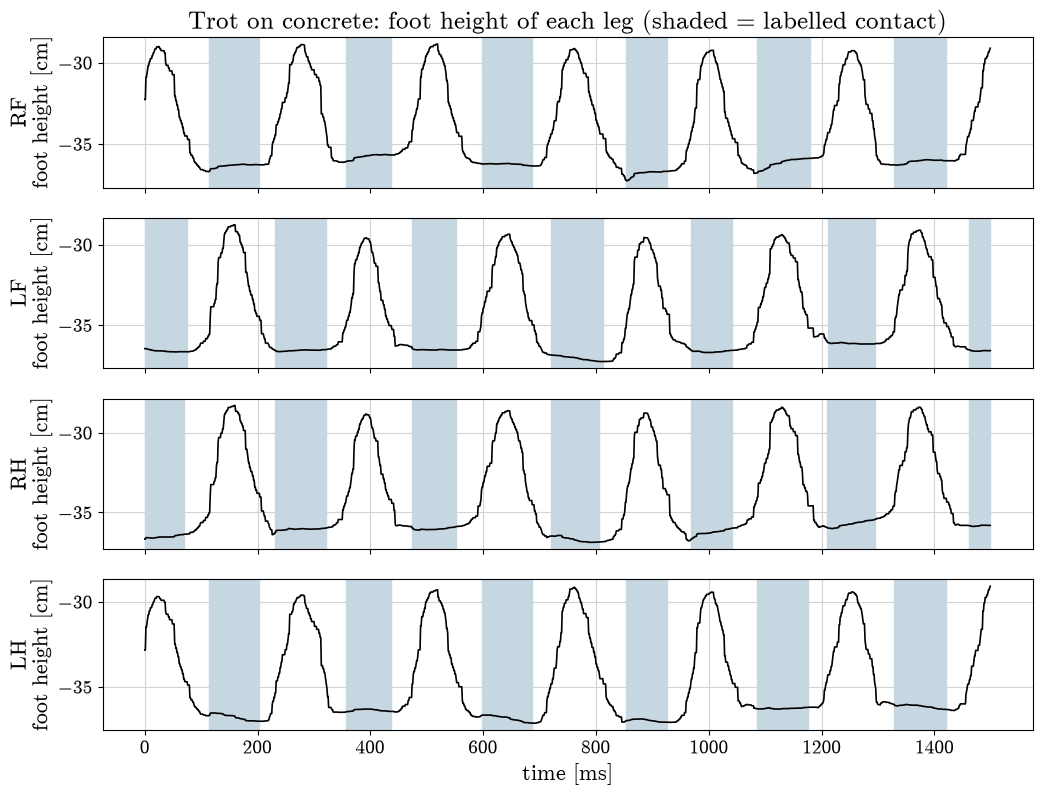

In [5]:
rec = "concrete_left_circle"
e = sp_a["test"][rec][:1500]
X, y = recs[rec]
fig, axes = plt.subplots(4, 1, sharex=True, figsize=(12, 9))
for k, (ax, leg) in enumerate(zip(axes, LEGS)):
    ax.fill_between(e - e[0], 0, 1, where=y[e, k] == 1, step="mid", color=LIGHT_GREY, transform=ax.get_xaxis_transform())
    ax.plot(e - e[0], 100 * X[e, P_Z[k]], color="k", lw=1.2)
    ax.set_ylabel(f"{leg}\nfoot height [cm]")
axes[0].set_title("Trot on concrete: foot height of each leg (shaded = labelled contact)")
axes[-1].set_xlabel("time [ms]")
save(fig, "data_labels"); plt.show()

## 2. Protocol (protocol A, the main one)

**Slide: sample and task.** A sample = the window of the last 150 timesteps (150 ms, the dataset paper's convention)
→ label = contact of the 4 feet at its **last** timestep, exactly as on the robot. Four independent binary problems,
one per leg.

**Slide: split.** The split is applied **to each recording separately**, in time:
`[ train 70% | gap | val 15% | gap | test 15% ]`, gaps one window long; every recording contributes to all three sets.
- **Contiguous blocks, not random windows**: consecutive samples are strongly correlated (the gait repeats every
  ~265 ms), so a random split puts near-copies of training windows in the test set and the score is optimistic
  (scikit-learn cross-validation guide; Arlot & Celisse 2010; Kapoor & Narayanan 2023 — see
  `reports/Time series splits and windowing.md`).
- **Gaps of one window**: no timestep is shared between two sets.
- **Overlapping windows inside each set**: training and validation take every 10th window (consecutive windows differ
  by 1 ms of 150, near-duplicates — 10× cheaper for the same information); **test scores every timestep**, as the
  robot would.

**Slide: tuning workflow and normalization.** `GridSearchCV` with a `PredefinedSplit` = one fixed train → val fold
(no k-fold: neighbouring windows are near-duplicates). The scaler is a step of the pipeline, so it is always fitted on
the data the model is fitted on: during the search `StandardScaler` learns mean / std on **train** only and is applied
to val; at the refit on **train + val** it is re-learned there and applied to test. Test is used once. Trees, forest
and boosting take the features unscaled (splits on thresholds do not depend on the scale).


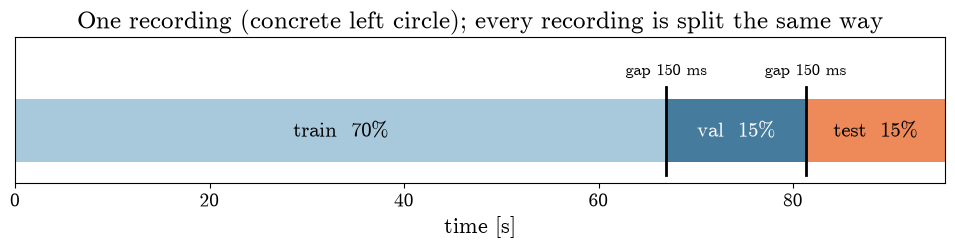

,windows at stride 1,windows used,stride,share of time
train,704688,70476,10,70%
val,148755,14882,10,15%
test,148763,148763,1,15%


In [6]:
# slide: one recording, to scale (the 150 ms gaps are too thin to see: marked with ticks)
rec = "concrete_left_circle"
n = len(recs[rec][0])
fig, ax = plt.subplots(figsize=(12, 1.9))
for part in ("train", "val", "test"):
    e = sp_a[part][rec]
    lo, hi = (e[0] - WINDOW + 1) / 1000, (e[-1] + 1) / 1000
    ax.barh(0, hi - lo, left=lo, color=SPLIT_COLORS[part], height=0.6)
    ax.text((lo + hi) / 2, 0, f"{part}  {round(100 * (hi - lo) / (n / 1000))}%", ha="center", va="center",
            color=text_color(SPLIT_COLORS[part]), fontsize=15)
for part in ("val", "test"):                       # gap = the window before the first val / test window
    g = (sp_a[part][rec][0] - WINDOW + 1) / 1000
    ax.plot([g, g], [-0.42, 0.42], color="k", lw=2)
    ax.text(g, 0.5, "gap 150 ms", ha="center", va="bottom", fontsize=12)
ax.set_xlim(0, n / 1000); ax.set_ylim(-0.5, 0.9); ax.set_yticks([]); ax.grid(False)
for side in ("left", "right", "top"):                  # no frame: only the time axis stays
    ax.spines[side].set_visible(False)
ax.set_xlabel("time [s]"); ax.set_title(f"Example split: the {rec.replace('_', ' ')} recording")
save(fig, "split_one_recording"); plt.show()

# set sizes: timesteps with a full window behind them (stride 1) and windows used (stride 10 for train / val)
sp_1 = split(recs, stride=1)
pd.DataFrame({part: {"windows at stride 1": sum(len(e) for e in sp_1[part].values()),
                     "windows used": sum(len(e) for e in sp_a[part].values()),
                     "stride": 10 if part != "test" else 1, "share of time": share}
              for part, share in zip(("train", "val", "test"), ("70%", "15%", "15%"))}).T


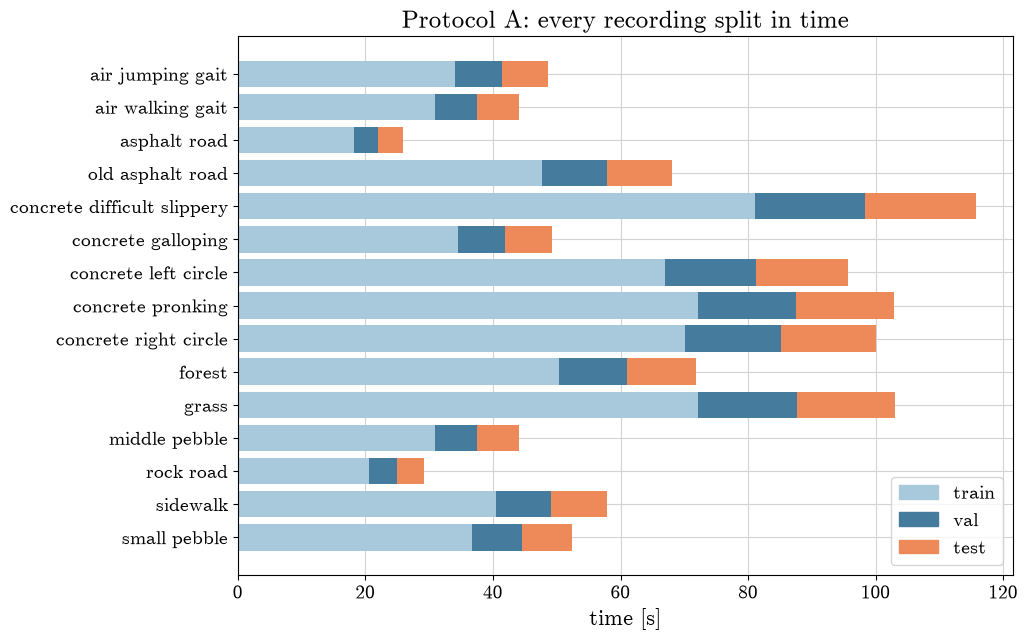

In [7]:
# backup slide: all recordings
fig, ax = plt.subplots(figsize=(10, 7))
names = list(recs)
for i, name in enumerate(names):
    for part in ("train", "val", "test"):
        e = sp_a[part][name]
        ax.barh(i, (e[-1] - e[0] + WINDOW) / 1000, left=(e[0] - WINDOW + 1) / 1000, color=SPLIT_COLORS[part])
ax.set_yticks(range(len(names)), [n.replace("_", " ") for n in names])  # cmr10 has no "_"
ax.invert_yaxis(); ax.set_xlabel("time [s]")
ax.legend(handles=[Patch(color=c, label=p) for p, c in SPLIT_COLORS.items()], loc="lower right")
ax.set_title("Protocol A: every recording split in time")
save(fig, "split_protocol_a"); plt.show()


**Slide: metric, imbalance, no class weights.** Each leg is a binary problem (contact = positive class). Main metric:
**F1 on contact, averaged over the legs**; beside it the **false-contact rate** (false contacts / true air timesteps,
the EKF's harmful error) and the missed-contact rate. Accuracy alone misleads: always answering "air" scores 0.665
accuracy but F1 = 0.

**No class weighting**, on purpose: the imbalance is mild (~1:2, the same for every leg); F1 on the contact class
already prevents "always air" from scoring; the models show **no majority-class bias** (recall ≥ precision below);
and up-weighting contact would make the models say "contact" more often — more false contacts, the harmful error.

In [8]:
summary(A, y_a, ["majority"] + KEPT)[["F1", "precision", "recall", "false contact", "missed contact"]].assign(
    accuracy=[A[m][0]["test"]["accuracy"] for m in ["majority"] + KEPT]).round(4)

,F1,precision,recall,false contact,missed contact,accuracy
majority baseline,0.0000,0.0000,0.0000,0.0000,1.0000,0.6648
ridge,0.9463,0.9383,0.9545,0.0317,0.0455,0.9637
kernel ridge,0.9558,0.9511,0.9604,0.0249,0.0395,0.9702
decision tree,0.9396,0.9378,0.9415,0.0315,0.0585,0.9595
random forest,0.9668,0.9651,0.9685,0.0177,0.0315,0.9777
gradient boosting,0.9720,0.9685,0.9756,0.0160,0.0244,0.9812


## 3. Input comparison — what to feed the model (ridge fixed)

Same model (ridge: least squares on ±1 targets + α‖w‖², contact if the score > 0), same split; only the input changes.
Choices inside each step were made on validation; each chosen input was tested once.

| input | values | what it adds |
|---|---|---|
| current timestep | 54 | one instant |
| raw window | 15 log-spaced lags × 54 = 810 | history: dense recent lags (0, 1, 2, 3, 5, 8 … ms), sparse old ones up to 149 ms |
| hand-crafted features | 390 | per channel: current value, change over 5 and 50 ms, window mean, std, min, max; per foot: height above its window minimum, speed now, mean speed over 20 ms |

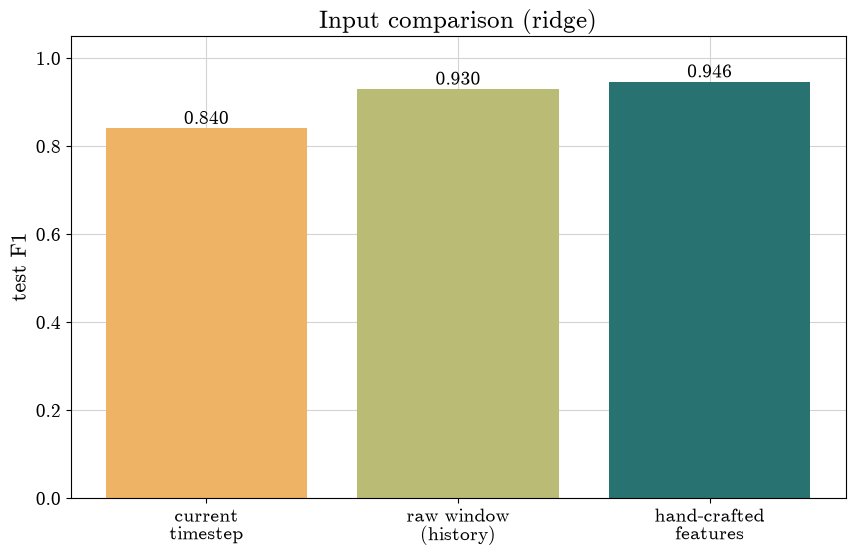

,F1,precision,recall,false contact,missed contact
"ridge, current timestep",0.8404,0.8720,0.8112,0.0601,0.1888
"ridge, raw window",0.9297,0.9344,0.9251,0.0327,0.0749
ridge,0.9463,0.9383,0.9545,0.0317,0.0455


In [9]:
inputs = ["ridge_current", "ridge_window_log", "ridge_feat_all"]
labels_inputs = ["current\ntimestep", "raw window\n(history)", "hand-crafted\nfeatures"]
# validation F1 of the chosen alpha: the input was chosen on validation, test not used for this choice
f1s = [max(v["val_f1"] for v in A[m][0]["validation"]) for m in inputs]
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(labels_inputs, f1s, color=INPUT_COLORS)
for b, v in zip(bars, f1s):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center")
ax.set_ylim(0, 1.05); ax.set_ylabel("validation F1"); ax.set_title("Input comparison (ridge, validation)")
save(fig, "input_comparison"); plt.show()
summary(A, y_a, inputs)[["F1", "precision", "recall", "false contact", "missed contact"]].round(4)

In [ ]:
# slide "From window to input": which samples of the 150 ms window inputs A and B take (one channel, real data)
from src.features import LAGS
rec, leg = "concrete_left_circle", "LF"
X = recs[rec][0]
t_end = sp_a["test"][rec][400]                           # any window: the label timestep of one test window
w = 100 * X[t_end - WINDOW + 1:t_end + 1, P_Z[LEGS.index(leg)]]   # foot height [cm], oldest -> newest
ago = np.arange(WINDOW - 1, -1, -1)                      # ms before the label
t = -ago                                                 # time relative to the label [ms]
for name, lags in [("input_A", np.array([0])), ("input_B", LAGS["window_log"])]:
    fig, ax = plt.subplots(figsize=(3.3, 1.3))
    ax.plot(t, w, color="0.6", lw=1.2)
    ax.plot(-lags, w[WINDOW - 1 - lags], "o", color=VAL_COLOR, ms=4.5)
    ax.set_xlim(-152, 3); ax.set_yticks([]); ax.grid(False)
    for side in ("left", "right", "top"):
        ax.spines[side].set_visible(False)
    ax.set_xticks([-150, -100, -50, 0]); ax.tick_params(labelsize=9)
    ax.set_xlabel("time relative to the label [ms]", fontsize=9)
    save(fig, name); plt.show()


In [10]:
by_rec_in = pd.DataFrame({NAMES[m]: per_recording(A[m][1], sp_a["test"], y_a) for m in inputs})
by_rec_in.round(3).rename_axis("test F1 per recording (air: false-contact rate)")

,"ridge, current timestep","ridge, raw window",ridge
test F1 per recording (air: false-contact rate),,,
air_jumping_gait,0.014,0.000,0.000
air_walking_gait,0.004,0.000,0.000
asphalt_road,0.935,0.966,0.963
old_asphalt_road,0.850,0.914,0.913
concrete_difficult_slippery,0.879,0.950,0.959
concrete_galloping,0.583,0.781,0.832
concrete_left_circle,0.911,0.964,0.965
concrete_pronking,0.608,0.906,0.958
concrete_right_circle,0.876,0.956,0.960


- **0 → 0.840 → 0.930 → 0.946**: one instant → history → features.
- **History (+9 points)** fixes exactly where one instant fails: pronking 0.61 → 0.91, galloping 0.58 → 0.78.
- **Features (+1.7)** gain on the same non-trot gaits again (pronking 0.96, galloping 0.83); the whole gain is *found*
  contacts (missed 7.5% → 4.6%, false contacts unchanged at ~3.2%).
- Why features help a linear model: the useful information is **non-linear** in the raw signals — spread, extremes,
  "foot at its lowest", "foot not moving" (the velocity is ≈ 0 in contact but positive *and* negative in swing).
  A linear model cannot build these from raw values; the features hand them over.

**Slide: why history — picture.** Pronking, left front leg, 1.5 s of the test block: in stance the foot is neither
still nor at a fixed height (its height changes by several cm, its speed stays around 0.5–1 m/s), so a threshold on
the current values cannot find it.

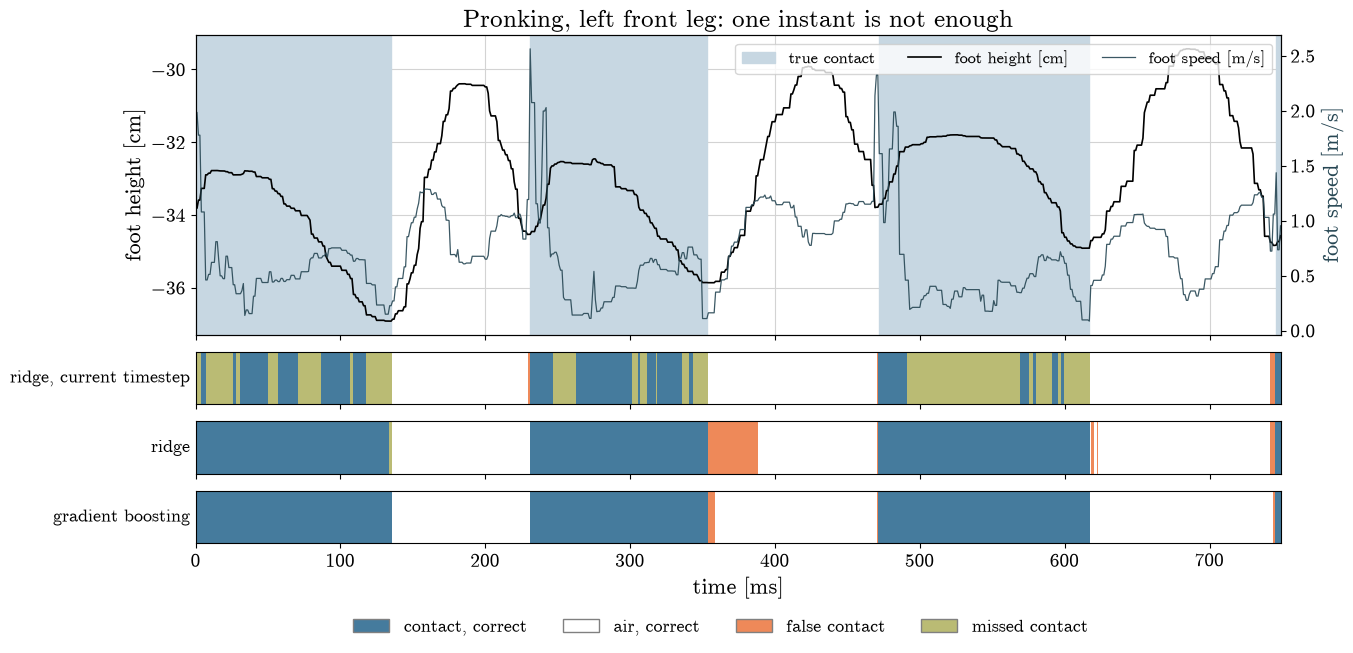

In [11]:
def outcome_colors(p, y):
    c = np.ones((len(p), 3))
    c[(p == 1) & (y == 1)] = OUTCOME_COLORS["contact, correct"]
    c[(p == 1) & (y == 0)] = OUTCOME_COLORS["false contact"]
    c[(p == 0) & (y == 1)] = OUTCOME_COLORS["missed contact"]
    return c

offset = dict(zip(sp_a["test"], np.cumsum([0] + [len(e) for e in sp_a["test"].values()])))

def strips(rec, models, leg="LF", start=0, n=450, title=None, name=None, labels=None):
    """Foot height and speed of `leg` over test timesteps [start, start + n) of `rec`, true contact shaded,
    one strip per model: blue contact (correct), red false contact, orange missed contact, white air (correct)."""
    k, (X, y) = LEGS.index(leg), recs[rec]
    e = sp_a["test"][rec][start:start + n]
    t, truth = e - e[0], y[e, k]
    fig, axes = plt.subplots(1 + len(models), 1, sharex=True, figsize=(14, 4.5 + 0.7 * len(models)),
                             gridspec_kw=dict(height_ratios=[4] + [0.7] * len(models), hspace=0.15))
    ax = axes[0]
    ax.fill_between(t, 0, 1, where=truth == 1, step="mid", color=LIGHT_GREY, transform=ax.get_xaxis_transform(),
                    label="true contact")
    ax.plot(t, 100 * X[e, P_Z[k]], color="k", lw=1.2, label="foot height [cm]")
    ax2 = ax.twinx()
    ax2.plot(t, np.linalg.norm(X[e][:, V_FOOT[k]], axis=1), color=FOOT_SPEED, lw=0.9, alpha=0.9, label="foot speed [m/s]")
    ax2.grid(False)
    ax.set_ylabel("foot height [cm]"); ax2.set_ylabel("foot speed [m/s]", color=FOOT_SPEED)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=12, ncol=3)
    ax.set_title(title or f"{rec}, {leg}")
    for m, a, lab in zip(models, axes[1:], labels or [NAMES[m] for m in models]):
        p = A[m][1][offset[rec] + start:offset[rec] + start + len(e), k]
        a.imshow(outcome_colors(p, truth)[None], aspect="auto", extent=(t[0], t[-1], 0, 1), interpolation="nearest")
        a.set_yticks([]); a.grid(False); a.set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=13)
    axes[-1].set_xlabel("time [ms]")
    fig.legend([Patch(facecolor=c, edgecolor="0.5") for c in OUTCOME_COLORS.values()], list(OUTCOME_COLORS),
               loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=4, fontsize=13, frameon=False)
    if name:
        save(fig, name)
    plt.show()

strips("concrete_pronking", ["ridge_current", "ridge_window_log", "ridge_feat_all"],
       labels=["ridge, current timestep", "ridge, raw window", "ridge, features"],
       title="Pronking, left front leg", name="why_history_pronking")

## 4. Model comparison — which model (input fixed: hand-crafted features)

Same input, same split, one binary model per leg; only the model changes.
- **Ridge**: a hyperplane, least squares on ±1 targets + α‖w‖².
- **Kernel ridge (RBF)**: the same loss and penalty, but the boundary is non-linear: f(x) = Σᵢ aᵢ k(xᵢ, x) with
  k(x, x′) = exp(−γ‖x − x′‖²). It works on pairs of training windows (an n × n kernel matrix), so it is trained on
  **10,000 windows** taken evenly in time: all 70k would need 40 GB of memory.
- **Decision tree**: greedy yes/no questions "feature ≤ threshold", each chosen to best separate contact from air;
  each leaf predicts its majority label. High variance: a slightly different training set gives a different tree.
- **Random forest**: 200 deep trees, each on a bootstrap sample of the windows and a random subset of features per
  split; their votes are averaged → **lower variance**.
- **Gradient boosting**: small trees added one at a time, each fitted to what the current ensemble still gets wrong
  (the gradient of the log-loss), scaled by a learning rate → **lower bias**.

Trees, forest and boosting use all 70k training windows (their cost grows ~n log n) and need no scaling.

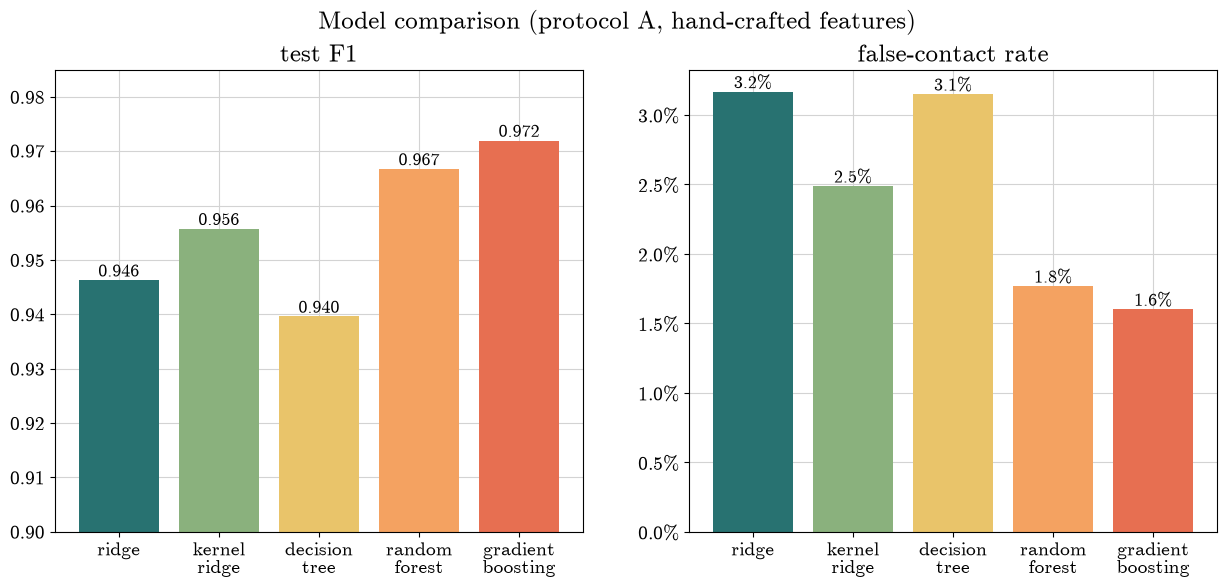

,F1,precision,recall,exact-state,false contact,missed contact,val F1
ridge,0.9463,0.9383,0.9545,0.8987,0.0317,0.0455,0.9513
kernel ridge,0.9558,0.9511,0.9604,0.9091,0.0249,0.0395,0.9633
decision tree,0.9396,0.9378,0.9415,0.8760,0.0315,0.0585,0.9507
random forest,0.9668,0.9651,0.9685,0.9278,0.0177,0.0315,0.9715
gradient boosting,0.9720,0.9685,0.9756,0.9368,0.0160,0.0244,0.9750


In [12]:
tab = summary(A, y_a, KEPT)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, col, title in [(axes[0], "F1", "test F1"), (axes[1], "false contact", "false-contact rate")]:
    v = tab[col]
    bars = ax.bar(range(len(v)), v, color=[COLORS[m] for m in KEPT])
    for b, x in zip(bars, v):
        ax.text(b.get_x() + b.get_width() / 2, x, f"{x:.3f}" if col == "F1" else f"{100 * x:.1f}%",
                ha="center", va="bottom", fontsize=13)
    ax.set_xticks(range(len(v)), [n.replace(" ", "\n") for n in v.index]); ax.set_title(title)
axes[0].set_ylim(0.9, 0.985)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.1f}%"))
fig.suptitle("Model comparison (protocol A, hand-crafted features)", fontsize=18)
save(fig, "model_comparison"); plt.show()
tab.round(4)

- **Ridge → kernel ridge (+1.0)**: the non-linear boundary helps on top of the features; both errors drop
  (false contacts 3.2% → 2.5%).
- **One tree is not enough (0.940)**: below ridge — the high variance of a single tree; most missed contacts of all.
- **Tree → forest (+2.7)**: averaging 200 decorrelated trees removes most of that variance — the largest step.
- **Forest → boosting (+0.5)**: lowering the bias adds less, but on both errors.
- **Gradient boosting is the best model: 0.972**, false contacts 1.6% (ridge 3.2%), missed 2.4%.
- Hyperparameters were chosen on validation for every model; the optima are flat (results do not hinge on tuning).

In [13]:
by_rec_m = pd.DataFrame({NAMES[m]: per_recording(A[m][1], sp_a["test"], y_a) for m in KEPT})
by_rec_m.round(3).rename_axis("test F1 per recording (air: false-contact rate)")

,ridge,kernel ridge,decision tree,random forest,gradient boosting
test F1 per recording (air: false-contact rate),,,,,
air_jumping_gait,0.000,0.000,0.002,0.000,0.000
air_walking_gait,0.000,0.000,0.044,0.000,0.000
asphalt_road,0.963,0.973,0.969,0.977,0.984
old_asphalt_road,0.913,0.929,0.906,0.938,0.944
concrete_difficult_slippery,0.959,0.964,0.963,0.977,0.980
concrete_galloping,0.832,0.868,0.799,0.893,0.914
concrete_left_circle,0.965,0.974,0.972,0.981,0.985
concrete_pronking,0.958,0.971,0.947,0.985,0.986
concrete_right_circle,0.960,0.966,0.960,0.978,0.983


**Slide: is the comparison fair?** Kernel ridge is limited to 10k windows by memory; the trees use all 70k. Training
gradient boosting on **the same 10k windows** separates the two effects.

In [14]:
eq = ["krr_feat_all", "gb_10k_feat_all", "gb_feat_all"]
summary(A, y_a, eq)[["F1", "false contact", "missed contact"]].round(4).assign(
    **{"training windows": ["10k", "10k", "70k"]})

,F1,false contact,missed contact,training windows
kernel ridge,0.9558,0.0249,0.0395,10k
"gradient boosting, 10k windows",0.9619,0.0219,0.0332,10k
gradient boosting,0.9720,0.0160,0.0244,70k


- **At equal data boosting still wins** (0.962 vs 0.956): of its +1.6 over kernel ridge, **~0.6 comes from the model and
  ~1.0 from the 7× more training windows** kernel ridge cannot use.

**Slide: what a tree learns.** A depth-3 tree for the RF leg, fitted on the training block only — for the picture,
not the tuned model.

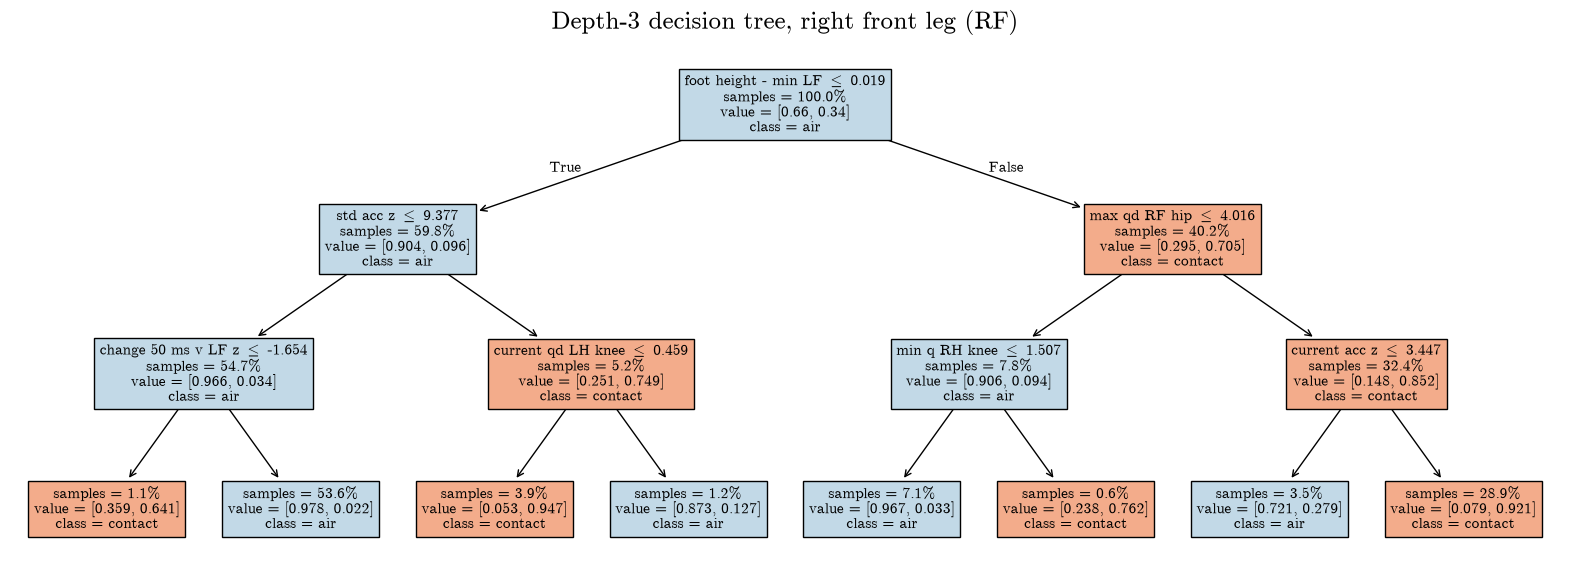

In [15]:
FEAT_GROUPS = {"current": 54, "change 5 ms": 54, "change 50 ms": 54, "mean": 54, "std": 54, "min": 54, "max": 54,
               "foot height - min": 4, "foot speed": 4, "foot speed 20 ms": 4}
CHANNELS = ([f"q {leg} {j}" for leg in LEGS for j in ("abad", "hip", "knee")]
            + [f"qd {leg} {j}" for leg in LEGS for j in ("abad", "hip", "knee")]
            + [f"acc {a}" for a in "xyz"] + [f"omega {a}" for a in "xyz"]
            + [f"p {leg} {a}" for leg in LEGS for a in "xyz"] + [f"v {leg} {a}" for leg in LEGS for a in "xyz"])
feat_type = np.repeat(list(FEAT_GROUPS), list(FEAT_GROUPS.values()))
feat_channel = np.array([CHANNELS[j % 54].split()[0] for j in range(378)] + ["p"] * 4 + ["v"] * 8)
FEAT_NAMES = ([f"{t} {CHANNELS[j % 54]}" for j, t in enumerate(feat_type[:378])]
              + [f"{t} {leg}" for t in list(FEAT_GROUPS)[7:] for leg in LEGS])

small = DecisionTreeClassifier(max_depth=3, random_state=0).fit(INPUTS["feat_all"](recs, sp_a["train"]),
                                                                labels(recs, sp_a["train"])[:, 0])
fig = plt.figure(figsize=(20, 7))
nodes = plot_tree(small, feature_names=FEAT_NAMES, class_names=["air", "contact"], filled=True, impurity=False,
                  proportion=True, precision=3, fontsize=11)
for t in nodes:                                   # cmr10 has no "<": use the maths symbol
    t.set_text(t.get_text().replace("<=", r"$\leq$"))
    if t.get_bbox_patch() is not None:            # recolour the boxes with the palette
        t.get_bbox_patch().set_facecolor(TREE_COLORS["contact" if "class = contact" in t.get_text() else "air"])
plt.title("Depth-3 decision tree, right front leg (RF)")
save(fig, "depth3_tree"); plt.show()

- **The first question is about the LF foot**, not RF's own: if LF is within 1.9 cm of its window minimum (LF on the
  ground), RF is in the air 90% of the time — LF and RF are on opposite trot pairs. The tree finds the leg coupling by
  itself.
- Thresholds are in physical units (no scaling needed). These 7 questions already classify ≈ 94% of the RF training
  windows (majority rule: 66%); the deep tuned trees refine the boundary cases.

**Slide: where the errors are.** For every error (all legs, ground recordings): its distance to the nearest true
touchdown or lift-off. Errors close to a transition are timing disagreements with a label that is itself a smoothed,
offline estimate; errors far from it are wrong contacts in the middle of a stance or swing.

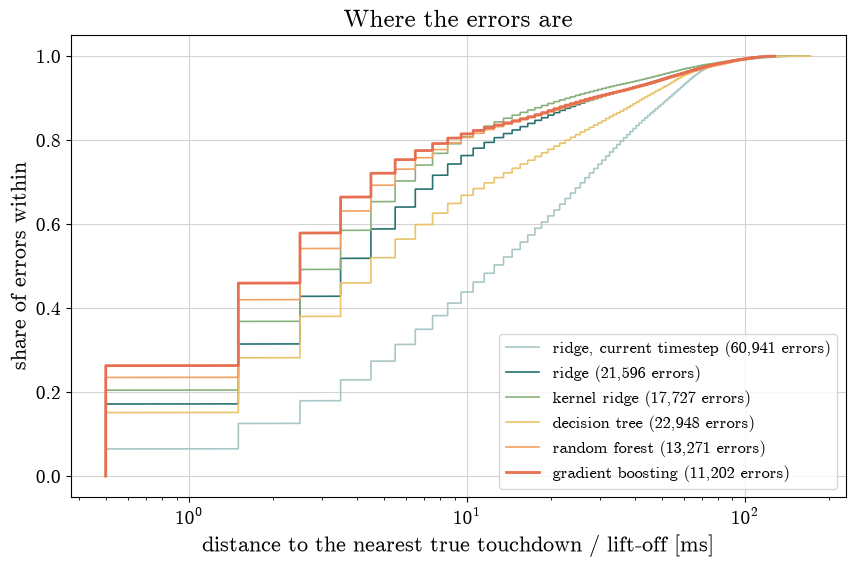

,errors,within 5 ms,within 10 ms,within 20 ms,median [ms]
"ridge, current timestep",60941.0,0.274,0.438,0.620,12.5
ridge,21596.0,0.588,0.763,0.860,3.5
kernel ridge,17727.0,0.654,0.808,0.887,3.5
decision tree,22948.0,0.520,0.669,0.778,4.5
random forest,13271.0,0.693,0.806,0.867,2.5
gradient boosting,11202.0,0.721,0.815,0.870,2.5


In [16]:
def error_distances(m):
    out = []
    for rec, e in sp_a["test"].items():
        y = recs[rec][1][e]
        if not y.any():
            continue                                          # air recordings: no transitions
        p = A[m][1][offset[rec]:offset[rec] + len(e)]
        for k in range(4):
            tr = np.flatnonzero(np.diff(y[:, k].astype(int))) + 0.5
            err = np.flatnonzero(p[:, k] != y[:, k])
            pos = np.clip(np.searchsorted(tr, err), 1, len(tr) - 1)
            out.append(np.minimum(np.abs(err - tr[pos - 1]), np.abs(err - tr[pos])))
    return np.concatenate(out)

err_models = ["ridge_current"] + KEPT
dist = {m: error_distances(m) for m in err_models}
fig, ax = plt.subplots(figsize=(10, 6))
for m, d in dist.items():
    x = np.sort(d)
    ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=COLORS_LINE[m], lw=2 if m == "gb_feat_all" else 1.2,
            label=f"{NAMES[m]} ({len(d):,} errors)")
ax.set_xscale("log"); ax.set_xlabel("distance to the nearest true touchdown / lift-off [ms]")
ax.set_ylabel("share of errors within"); ax.legend(fontsize=12)
ax.set_title("Where the errors are")
save(fig, "error_timing"); plt.show()
pd.DataFrame({NAMES[m]: {"errors": len(d), **{f"within {w} ms": np.mean(d <= w) for w in (5, 10, 20)},
                         "median [ms]": np.median(d)} for m, d in dist.items()}).T.round(3)

- **72% of gradient boosting's errors are within 5 ms of a true transition** (median 2.5 ms); joint and foot data
  update only every ~2–5 ms, so these are disagreements of one or two sensor readings about *when* the foot touched
  down — not wrong contacts.
- Ridge on the current timestep: only 27% within 5 ms (median 12.5 ms). **The better the model, the more its errors
  move to the transitions.**

**Slide (optional): the easy case, trot** — boosting's errors are slivers at the edges of each stance.

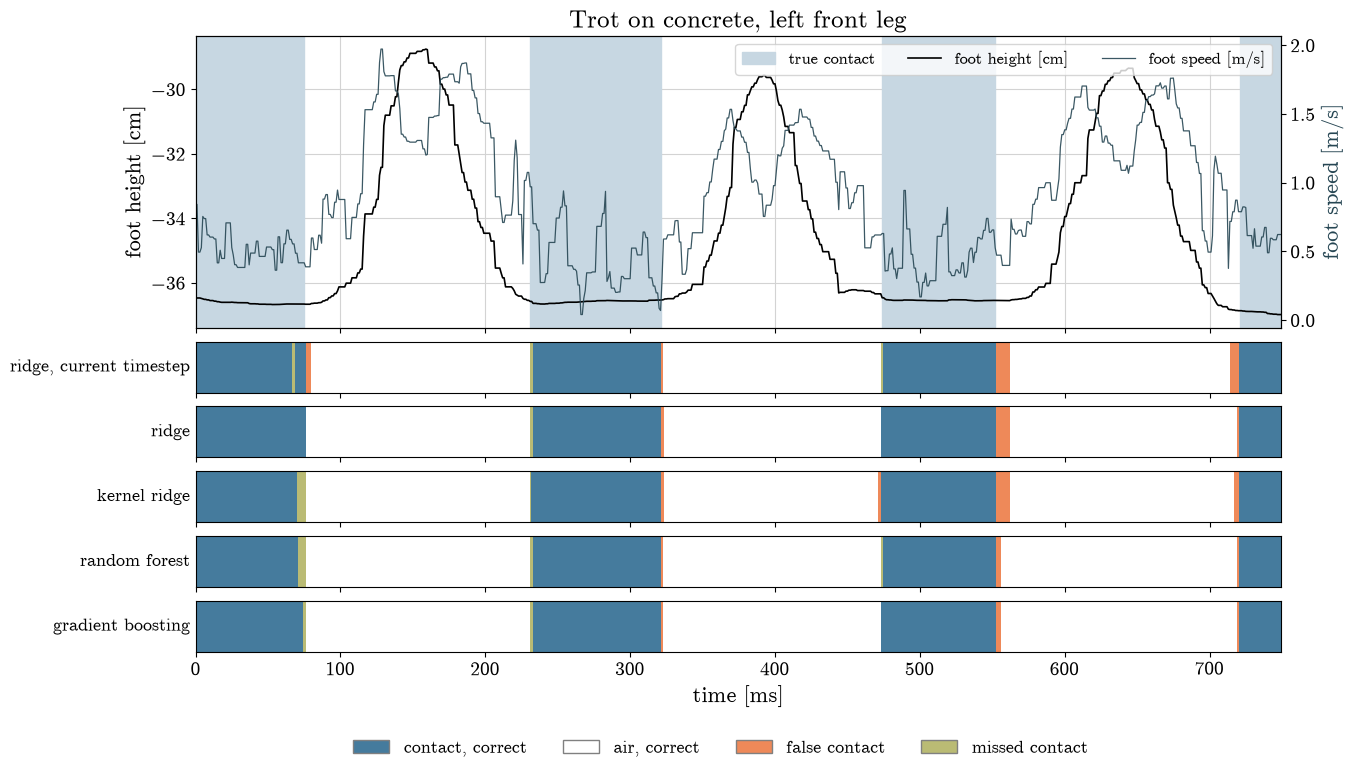

In [17]:
strips("concrete_left_circle", ["ridge_current", "ridge_feat_all", "krr_feat_all", "rf_feat_all", "gb_feat_all"],
       title="Trot on concrete, left front leg", name="strips_trot")

## 5. Unseen recordings — protocol B

**Slide: setup.** The split used by the published models on this dataset (Ordonez-Apraez et al. 2023; MI-HGNN;
MS-HGNN): **5 whole recordings never seen in training** (`air_jumping_gait`, `concrete_pronking`,
`concrete_right_circle`, `forest`, `small_pebble`); every other recording → first 85% train, gap, last 15% validation.
Same models, grids and refit as protocol A.
`concrete_pronking` is the dataset's **only pronking recording**: under protocol B the whole pronking gait is unseen
in training.

In [18]:
rows_b = np.concatenate([np.full(len(e), n) for n, e in sp_b["test"].items()])
keep = rows_b != "concrete_pronking"
print("windows: " + ", ".join(f"{p} {sum(len(e) for e in sp_b[p].values()):,}" for p in sp_b))
print(f"share of test contacts in concrete_pronking: {y_b[~keep].sum() / y_b.sum():.2f}")
cmp_b = pd.DataFrame({NAMES[m]: {"F1 A (seen)": A[m][0]["test"]["f1"], "F1 B (unseen)": B[m][0]["test"]["f1"],
                                 "change [points]": 100 * (B[m][0]["test"]["f1"] - A[m][0]["test"]["f1"]),
                                 "F1 B without pronking": f1(B[m][1][keep], y_b[keep]),
                                 "F1 B pronking only": f1(B[m][1][~keep], y_b[~keep]),
                                 "precision B": B[m][0]["test"]["precision"], "recall B": B[m][0]["test"]["recall"],
                                 **{f"{k} B": v for k, v in rates(B[m][1], y_b).items()}} for m in KEPT}).T
cmp_b.round(4)

windows: train 53,686, val 9,330, test 375,162
share of test contacts in concrete_pronking: 0.42


,F1 A (seen),F1 B (unseen),change [points],F1 B without pronking,F1 B pronking only,precision B,recall B,false contact B,missed contact B
ridge,0.9463,0.9215,-2.4825,0.9501,0.8797,0.9521,0.8928,0.0246,0.1072
kernel ridge,0.9558,0.9314,-2.4368,0.9560,0.8990,0.9341,0.9302,0.0377,0.0698
decision tree,0.9396,0.8560,-8.3616,0.9051,0.7748,0.8739,0.8417,0.0677,0.1583
random forest,0.9668,0.9346,-3.2180,0.9664,0.8867,0.9710,0.9011,0.0150,0.0989
gradient boosting,0.9720,0.9379,-3.4064,0.9704,0.8892,0.9701,0.9080,0.0154,0.0920


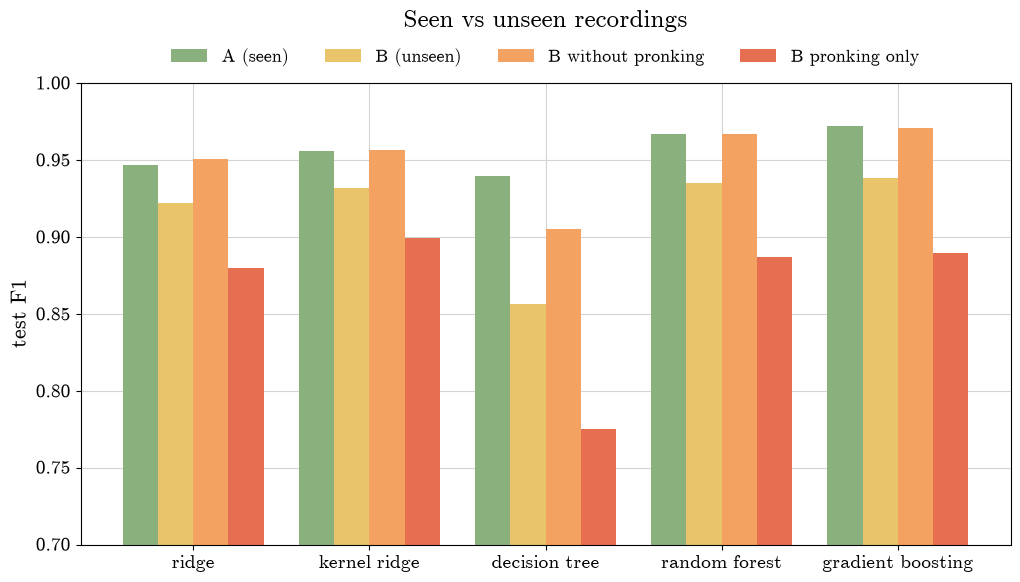

In [19]:
fig, ax = plt.subplots(figsize=(12, 6))
cols = ["F1 A (seen)", "F1 B (unseen)", "F1 B without pronking", "F1 B pronking only"]
w = 0.2
for i, col in enumerate(cols):
    ax.bar(np.arange(len(KEPT)) + (i - 1.5) * w, cmp_b[col], w, label=col.replace("F1 ", ""),
           color=PROTOCOL_B_COLORS[i])
ax.set_xticks(range(len(KEPT)), [NAMES[m] for m in KEPT]); ax.set_ylim(0.7, 1.0); ax.set_ylabel("test F1")
ax.legend(fontsize=13, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax.set_title("Seen vs unseen recordings", pad=40)
save(fig, "protocol_b"); plt.show()

- **Every model loses on unseen recordings**: −2.4 (ridge, kernel ridge) to −3.4 points (boosting); the single tree
  −8.4. **Gradient boosting stays best: 0.938.**
- **The drop is the unseen gait.** Without pronking, ridge, kernel ridge, the forest and boosting score at their protocol A
  level (boosting 0.970 vs 0.972; only the single tree stays well below): **a new terrain with a known gait costs almost nothing.** Pronking alone: 0.88–0.90 for the best models.
- **The errors are missed contacts, the safe side for the EKF**: boosting and the forest keep false contacts at 1.5%
  (precision 0.97) while recall drops to 0.90–0.91. Kernel ridge is the exception (3.8% false contacts).

**Slide: against published models (same split).** Published numbers: MS-HGNN paper (arXiv 2412.01297, Table 2),
mean ± std over 4 runs; deep networks on the raw 150 × 54 window, ~635k training + validation windows. Same metrics:
legs-average F1 = our F1; 16-state accuracy = our exact-state accuracy (all 4 legs right).

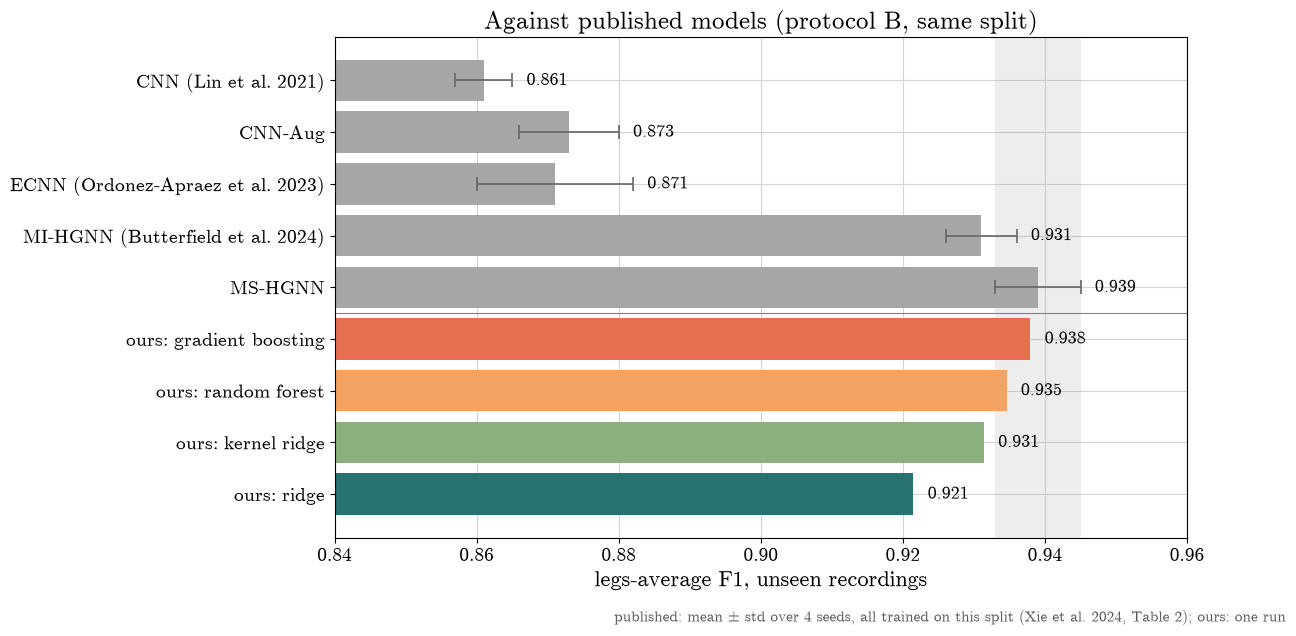

,F1,± F1,16-state accuracy
CNN (Lin et al. 2021),0.861,0.004,0.731
CNN-Aug,0.873,0.007,0.778
ECNN (Ordonez-Apraez et al. 2023),0.871,0.011,0.788
MI-HGNN (Butterfield et al. 2024),0.931,0.005,0.870
MS-HGNN,0.939,0.006,0.875
ours: gradient boosting,0.938,NaN,0.888
ours: random forest,0.935,NaN,0.890
ours: kernel ridge,0.931,NaN,0.853
ours: ridge,0.921,NaN,0.877


In [20]:
papers = pd.DataFrame({"CNN (Lin et al. 2021)": (0.861, 0.004, 0.731), "CNN-Aug": (0.873, 0.007, 0.778),
                       "ECNN (Ordonez-Apraez et al. 2023)": (0.871, 0.011, 0.788),
                       "MI-HGNN (Butterfield et al. 2024)": (0.931, 0.005, 0.870), "MS-HGNN": (0.939, 0.006, 0.875)},
                      index=["F1", "± F1", "16-state accuracy"]).T
ours = pd.DataFrame({f"ours: {NAMES[m]}": {"F1": B[m][0]["test"]["f1"], "16-state accuracy": B[m][0]["test"]["exact"]}
                     for m in ["gb_feat_all", "rf_feat_all", "krr_feat_all", "ridge_feat_all"]}).T
comp = pd.concat([papers, ours])
# published: mean ± std over 4 training seeds (thin dark-grey whiskers); ours: one run (no seed spread to show)
fig, ax = plt.subplots(figsize=(11, 6.5))
c = [GREY] * len(papers) + [COLORS[m] for m in ["gb_feat_all", "rf_feat_all", "krr_feat_all", "ridge_feat_all"]]
best = papers.loc["MS-HGNN"]
ax.axvspan(best["F1"] - best["± F1"], best["F1"] + best["± F1"], color=GREY, alpha=0.2, lw=0)   # best published ± std
ax.barh(range(len(comp)), comp["F1"], color=c)
err = comp["± F1"].fillna(0)
ax.errorbar(comp["F1"][:len(papers)], range(len(papers)), xerr=err[:len(papers)], fmt="none", ecolor="0.4",
            elinewidth=1.2, capsize=5, capthick=1.2)
for i, (v, s) in enumerate(zip(comp["F1"], err)):
    ax.text(v + s + 0.002, i, f"{v:.3f}", va="center", fontsize=13)
ax.axhline(len(papers) - 0.5, color="0.5", lw=0.8)
ax.set_yticks(range(len(comp)), comp.index); ax.invert_yaxis(); ax.set_xlim(0.84, 0.96)
ax.set_xlabel("legs-average F1, unseen recordings")
ax.set_title("Against published models (protocol B, same split)")
fig.text(0.99, -0.02, r"published: mean $\pm$ std over 4 seeds, all trained on this split (Xie et al. 2024, Table 2); "
         "ours: one run", ha="right", fontsize=11, color="0.35")
save(fig, "papers_comparison"); plt.show()
comp.round(3)

- **Gradient boosting on hand-crafted features is level with the best published model**: 0.938 vs MS-HGNN
  0.939 ± 0.006 (within its run-to-run spread), above MI-HGNN 0.931; on 16-state accuracy boosting (0.888) and the
  forest (0.890) are above both.
- **+7.7 points over the dataset paper's CNN**, with no neural network and ~10× fewer training windows.
- Not a perfectly matched comparison: we drop the last 300 ms of each recording (label artefact), refit on
  train + validation (they train on train only), and report one run (theirs: mean of 4 seeds).

## 6. Limits and conclusion

**Slide: limits.**
- The labels are themselves an estimate (offline, from foot height): part of the remaining errors — and of galloping's
  low score, where every model disagrees with the label in the same stretches — is probably label noise.
- Not run on the robot: in Python one prediction call takes ~15 ms for the tree ensembles (the budget at 1 kHz is
  1 ms); the computation itself fits (0.05–0.6 ms), but deployment would need compiled trees.
- One fixed validation block per recording (no repeated hold-out).
- A gait never seen in training (pronking under protocol B) remains hard: 0.88–0.90.

**Slide: conclusion.**
- **History → features → tree ensembles: 0 → 0.840 → 0.946 → 0.972** on seen recordings; false contacts 1.6%.
- The best model's errors sit at touchdown / lift-off, within a few milliseconds of the label.
- **On unseen recordings 0.938, level with the published state of the art** — a new terrain costs almost nothing,
  an unseen gait does.

**Backup (other notebooks):** SVMs and the boundary × loss 2 × 2 (`02_results` 3.1); window-lag and feature-group
choices (`02_results` 2.1–2.2); raw window vs features for boosting (`04_appendix` 3); stride experiments
(`04_appendix` 1); real-time timing and other weak spots (`PROGRESS.md`); literature on splits and windows
(`reports/Time series splits and windowing.md`).

## 7. Model cards

One card per presented model, protocol A (texts as in `02_results`, whose section numbers they refer to):
validation search (curve, or heatmap / 3-D surface for two hyperparameters — `VAL_PLOT_3D`), per-leg confusion
matrices (% of the true class), test scores, and the **16-state confusion matrix**: the 4 legs together as one of
16 contact states (bits in leg order RF LF RH LH, e.g. `1001` = RF and LH in contact), rows = true state, % of the
true state; the diagonal is exact-state accuracy. Figures saved as `val_<model>`, `cm_<model>`, `cm16_<model>`.

In [21]:
def model_card(name):
    """Validation search, per-leg confusion matrices and test scores of a protocol A model."""
    res, p = A[name]
    val = res["validation"]
    params = list(val[0]["params"]) if len(val) > 1 else []
    short = lambda s: s.split("__")[-1]
    # kernel models search gamma = s / d (d = number of inputs, src/models.py): the axis shows s
    # course notation: lambda for the ridge / kernel ridge regularization (scikit-learn calls it alpha)
    names = {"gamma_scale": r"$s$  ($\gamma = s\,/\,d$)", "alpha": r"$\lambda$"}
    label = lambda s: names.get(short(s), short(s).replace("_", " "))   # cmr10 has no "_"
    num = lambda x: int(np.sqrt(390)) / 390 if x == "sqrt" else x   # rf max_features: "sqrt" = 19 of 390 features
    if len(params) == 1:
        (param,) = params
        x, f = [v["params"][param] for v in val], [v["val_f1"] for v in val]
        b = int(np.argmax(f))
        fig, ax = plt.subplots(figsize=(10, 5))
        ax.semilogx(x, f, "o-", color=VAL_COLOR)
        ax.semilogx(x[b], f[b], "o", color=ACCENT, ms=11,
                    label=f"chosen: {label(param)} = {x[b]:g}, F1 {f[b]:.4f}")
        ax.set_xlabel(label(param)); ax.set_ylabel("validation F1"); ax.set_title(f"{NAMES[name]}: validation curve")
        ax.legend(loc="lower left")
        save(fig, f"val_{name}"); plt.show()
    elif len(params) == 2:
        grid = pd.DataFrame([{label(k): num(v["params"][k]) for k in params} | {"F1": v["val_f1"]} for v in val])
        grid = grid.pivot(index=label(params[0]), columns=label(params[1]), values="F1")
        F, (ib, jb) = grid.values, np.unravel_index(np.argmax(grid.values), grid.shape)
        if VAL_PLOT_3D:
            gx, gy = np.meshgrid(np.log10(grid.columns.astype(float)), np.log10(grid.index.astype(float)))
            fig = plt.figure(figsize=(12, 9))
            ax = fig.add_subplot(projection="3d", computed_zorder=False)
            ax.plot_surface(gx, gy, F, cmap=tint_cmap(VAL_COLOR, 0.8), alpha=0.9, edgecolor="grey", linewidth=0.3, zorder=1)
            ax.scatter(gx, gy, F, color="k", s=10, zorder=2, depthshade=False)
            ax.scatter(gx[ib, jb], gy[ib, jb], F[ib, jb], color=ACCENT, s=90, zorder=3,
                       depthshade=False)
            ax.text(gx[ib, jb], gy[ib, jb], F[ib, jb] + min(0.003, 0.1 * np.ptp(F)), f"chosen {F[ib, jb]:.4f}",
                    color=ACCENT, zorder=4, bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
            ax.set_xlabel(f"log10 {grid.columns.name}", labelpad=10); ax.set_ylabel(f"log10 {grid.index.name}", labelpad=10)
            ax.set_zlabel("validation F1", labelpad=24); ax.set_title(f"{NAMES[name]}: validation F1")
            ax.tick_params(axis="z", pad=10)
            ax.view_init(elev=28, azim=-50); ax.set_box_aspect(None, zoom=0.78)
        else:
            fig, ax = plt.subplots(figsize=(1.6 * grid.shape[1] + 2.5, 0.9 * grid.shape[0] + 2))
            ax.imshow(F, cmap=tint_cmap(VAL_COLOR), aspect="auto"); ax.grid(False)
            for i in range(grid.shape[0]):
                for j in range(grid.shape[1]):
                    ax.text(j, i, f"{F[i, j]:.4f}", ha="center", va="center", fontsize=12,
                            fontweight="bold" if (i, j) == (ib, jb) else "normal")
            ax.add_patch(plt.Rectangle((jb - 0.5, ib - 0.5), 1, 1, fill=False, color=ACCENT, lw=3))
            tick = lambda v: f"{v:.2g}" if v < 1 else f"{v:g}"
            ax.set_xticks(range(grid.shape[1]), [tick(v) for v in grid.columns])
            ax.set_yticks(range(grid.shape[0]), [tick(v) for v in grid.index])
            ax.set_xlabel(grid.columns.name); ax.set_ylabel(grid.index.name)
            ax.set_title(f"{NAMES[name]}: validation F1")
        save(fig, f"val_{name}"); plt.tight_layout(); plt.show()
    fig, axes = plt.subplots(2, 2, figsize=(9, 8.5))
    for k, (ax, leg) in enumerate(zip(axes.flat, LEGS)):
        cm = confusion_matrix(y_a[:, k], p[:, k], labels=[0, 1])
        pct = 100 * cm / cm.sum(1, keepdims=True)
        ax.imshow(pct, cmap=CM_CMAP, vmin=0, vmax=100); ax.grid(False)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{pct[i, j]:.1f}%\n({cm[i, j]:,})", ha="center", va="center", fontsize=13,
                        color=text_color(CM_CMAP(pct[i, j] / 100)))
        ax.set_xticks([0, 1], ["air", "contact"]); ax.set_yticks([0, 1], ["air", "contact"])
        ax.set_xlabel("predicted" if k >= 2 else ""); ax.set_ylabel("true" if k % 2 == 0 else ""); ax.set_title(leg)
    fig.suptitle(f"{NAMES[name]}: confusion matrices\n(% of the true class)", fontsize=18)
    plt.tight_layout(); save(fig, f"cm_{name}"); plt.show()
    cm_row(name)
    t = res["test"]
    display(pd.DataFrame({**{leg: t["per_leg"][leg] for leg in LEGS},
                          "mean": {m: t[m] for m in ("f1", "precision", "recall", "accuracy")}}).T.round(4))
    print(f"exact-state accuracy (all 4 legs right): {t['exact']:.4f}")


def cm_row(name):
    """The 4 per-leg confusion matrices in one row, drawn at slide size (6.7 in wide) so the text stays readable."""
    p = A[name][1]
    fig, axes = plt.subplots(1, 4, figsize=(6.7, 2.05))
    for k, (ax, leg) in enumerate(zip(axes, LEGS)):
        cm = confusion_matrix(y_a[:, k], p[:, k], labels=[0, 1])
        pct = 100 * cm / cm.sum(1, keepdims=True)
        ax.imshow(pct, cmap=CM_CMAP, vmin=0, vmax=100); ax.grid(False)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{pct[i, j]:.1f}%", ha="center", va="center", fontsize=10,
                        color=text_color(CM_CMAP(pct[i, j] / 100)))
        ax.set_xticks([0, 1], ["air", "contact"], fontsize=8)
        ax.set_yticks([0, 1], ["air", "contact"] if k == 0 else ["", ""], fontsize=8)
        ax.tick_params(length=0); ax.set_title(leg, fontsize=11, pad=3)
    axes[0].set_ylabel("true", fontsize=9)
    fig.supxlabel("predicted (% of the true class)", fontsize=9, y=0.02)
    plt.tight_layout(w_pad=0.6); save(fig, f"cmrow_{name}"); plt.show()

STATES = [format(s, "04b") for s in range(16)]             # bits in leg order RF LF RH LH

def to_state(y):
    return y.astype(int) @ (1 << np.arange(3, -1, -1))

def state_confusion(name):
    """16-state confusion matrix (4 legs together), % of the true state."""
    ys, ps = to_state(y_a), to_state(A[name][1])
    cm = np.zeros((16, 16), int)
    np.add.at(cm, (ys, ps), 1)
    pct = 100 * cm / np.maximum(cm.sum(1, keepdims=True), 1)
    share = cm.sum(1) / cm.sum()
    fig, ax = plt.subplots(figsize=(12, 11))
    ax.imshow(pct, cmap=CM_CMAP, vmin=0, vmax=100); ax.grid(False)
    for i in range(16):
        for j in range(16):
            if cm[i, j]:
                ax.text(j, i, f"{pct[i, j]:.0f}", ha="center", va="center", fontsize=9,
                        color=text_color(CM_CMAP(pct[i, j] / 100)))
    ax.set_xticks(range(16), STATES, rotation=90, fontsize=11)
    ax.set_yticks(range(16), [f"{s} ({100 * w:.1f}%)" for s, w in zip(STATES, share)], fontsize=11)
    ax.set_xlabel("predicted state (RF LF RH LH)"); ax.set_ylabel("true state (share of test timesteps)")
    ax.set_title(f"{NAMES[name]}: 16-state confusion (% of true state), exact-state {np.trace(cm) / cm.sum():.3f}")
    save(fig, f"cm16_{name}"); plt.show()

### 7.1 Ridge — current timestep (54 inputs)

Standardized inputs → `RidgeClassifier` (least squares on ±1 targets + α‖w‖², contact if score > 0),
one fit for the 4 legs. α chosen on validation (train-only fit), then refit on train+val.

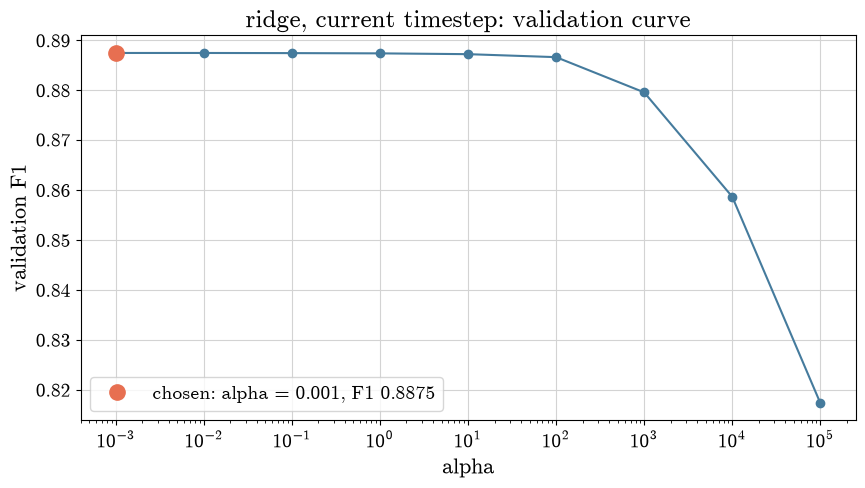

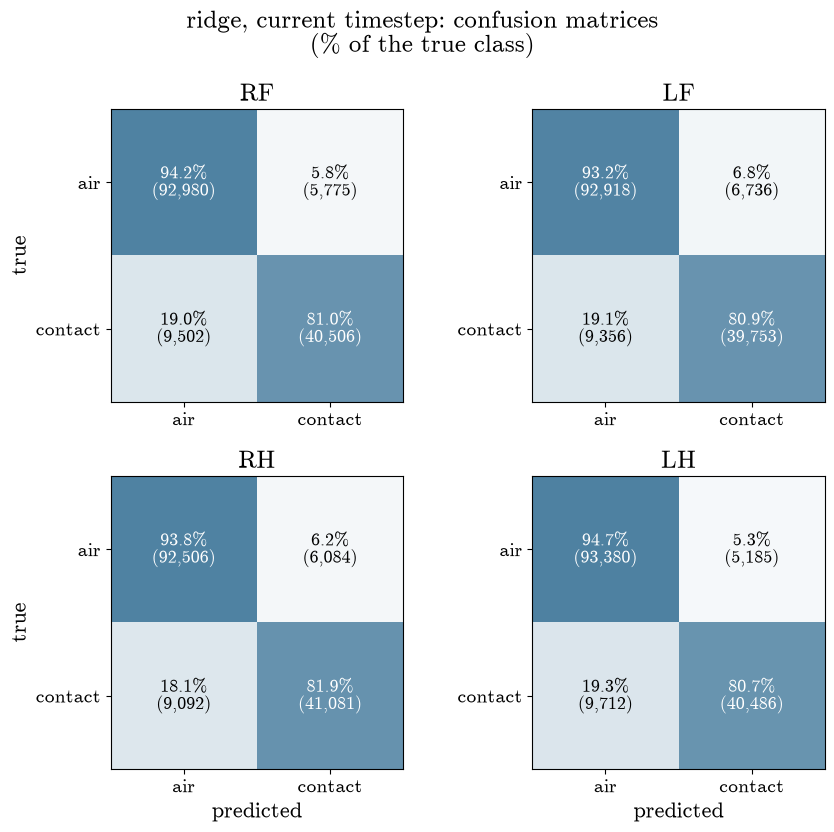

,f1,precision,recall,accuracy
RF,0.8413,0.8752,0.8100,0.8973
LF,0.8317,0.8551,0.8095,0.8918
RH,0.8441,0.8710,0.8188,0.8980
LH,0.8446,0.8865,0.8065,0.8999
mean,0.8404,0.8720,0.8112,0.8967


exact-state accuracy (all 4 legs right): 0.7992


In [22]:
model_card("ridge_current")

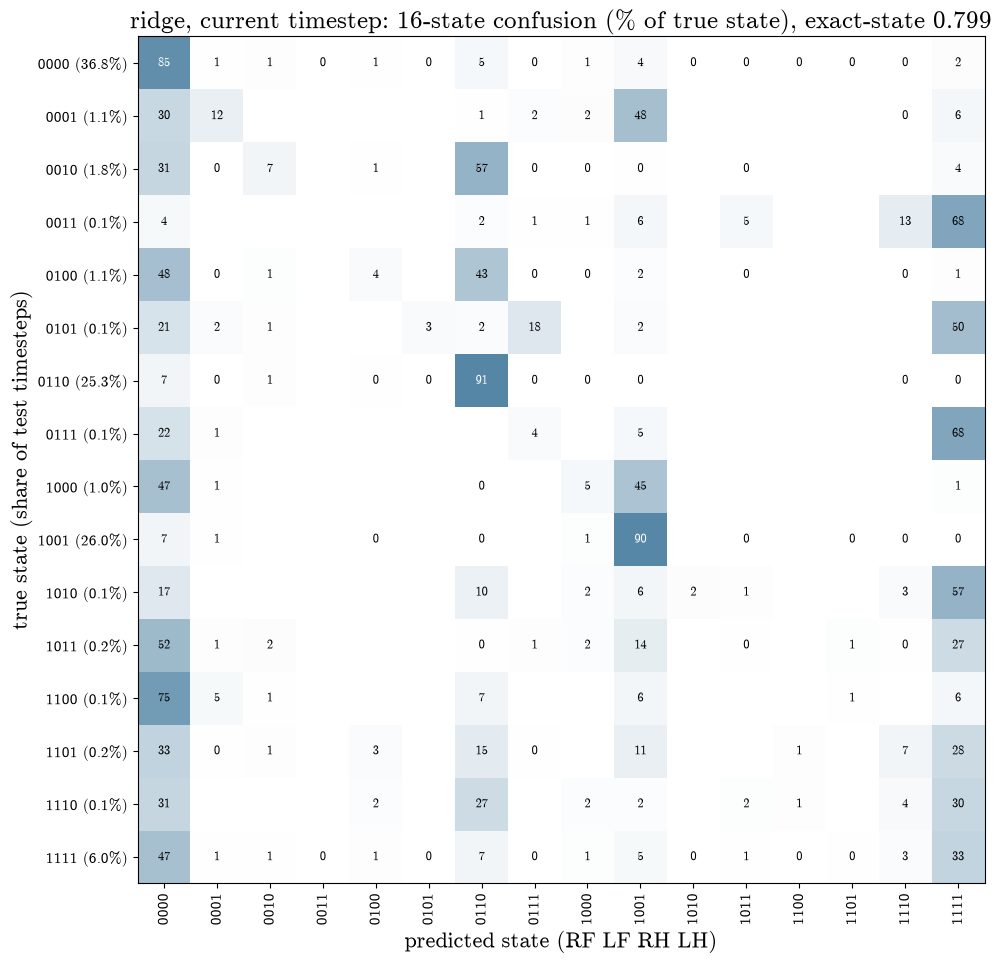

In [23]:
state_confusion("ridge_current")

- **Validation curve flat** for every α up to 10, falling only when the penalty squashes the weights. The best α
  is on the grid's lower edge, but the curve is already flat there (ridge → ordinary least squares). With ~85k
  samples and 54 weights there is nothing to over-fit: the model **under-fits** — the limit is the linear
  boundary, not the tuning (same conclusion as the EMG project).
- Precision 0.87 > recall 0.81: errors are mostly **missed contacts**, the safe side for the EKF. Least squares
  on a 32/68 problem leans towards the majority class.
- Weak on **pronking (0.61) and galloping (0.58)** (section 1): most training data is trot, and one hyperplane is
  fitted mostly to it. Validation (0.888) > test (0.840): the gap concentrates in these recordings, where the gait
  drifts between the middle (val) and the end (test) of the recording.

### 7.2 Ridge — raw window (`window_log`, 810 inputs)

Same model; input = the 54 channels at 15 log-spaced lags over the last 150 ms (chosen in section 2.1).

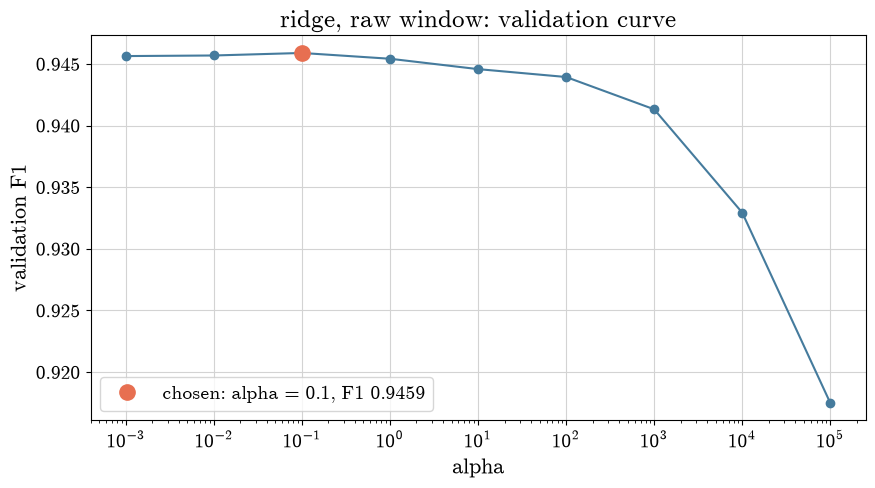

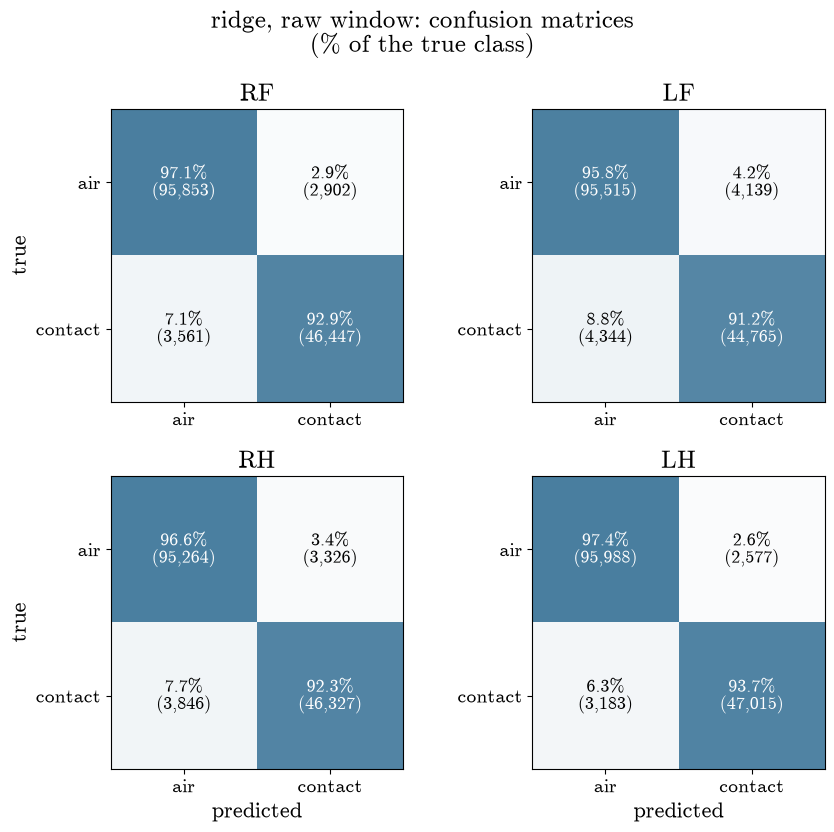

,f1,precision,recall,accuracy
RF,0.9350,0.9412,0.9288,0.9566
LF,0.9135,0.9154,0.9115,0.9430
RH,0.9282,0.9330,0.9233,0.9518
LH,0.9423,0.9480,0.9366,0.9613
mean,0.9297,0.9344,0.9251,0.9532


exact-state accuracy (all 4 legs right): 0.8789


In [24]:
model_card("ridge_window_log")

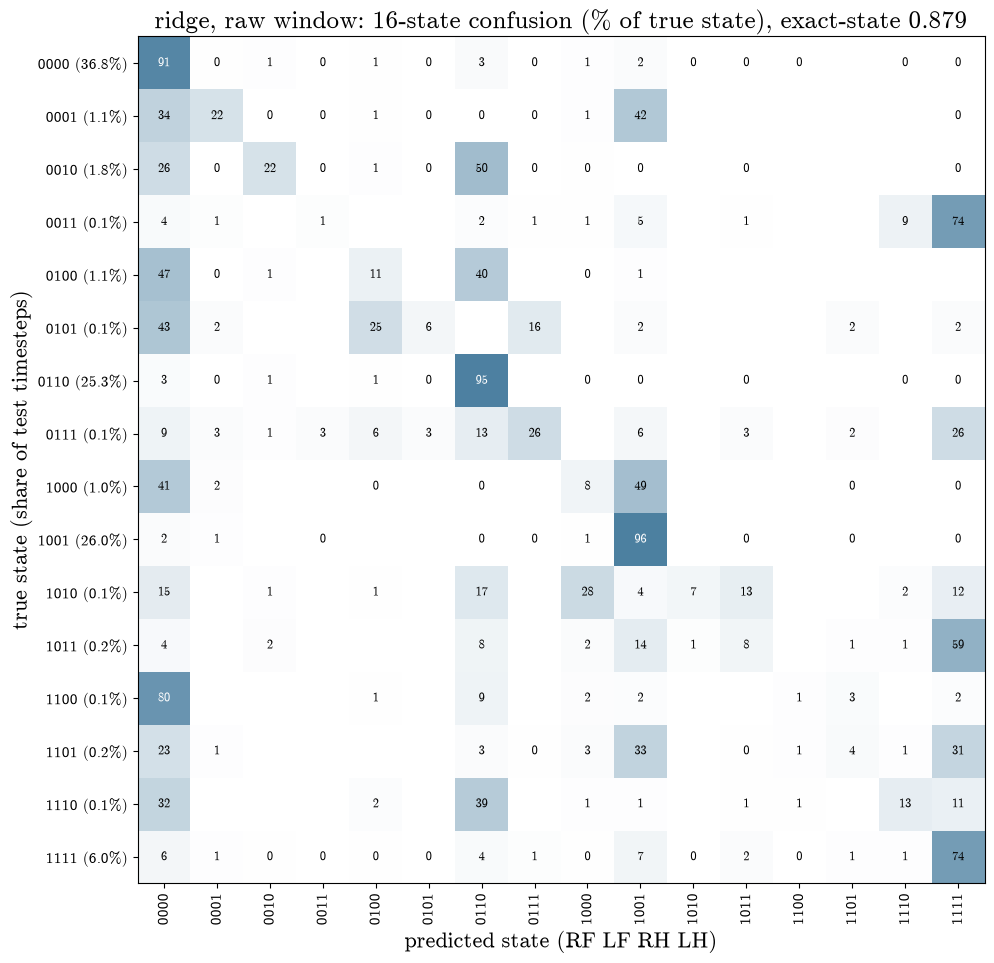

In [25]:
state_confusion("ridge_window_log")

- α flat again (best 0.1): still under-fitting, now with 810 weights.
- Precision and recall balanced (0.93 / 0.93); LF the hardest leg (0.914).

### 7.3 Ridge — hand-crafted features (`feat_all`, 390 inputs)

Same model; input = the feature groups g1 + g2 (chosen in section 2.2).

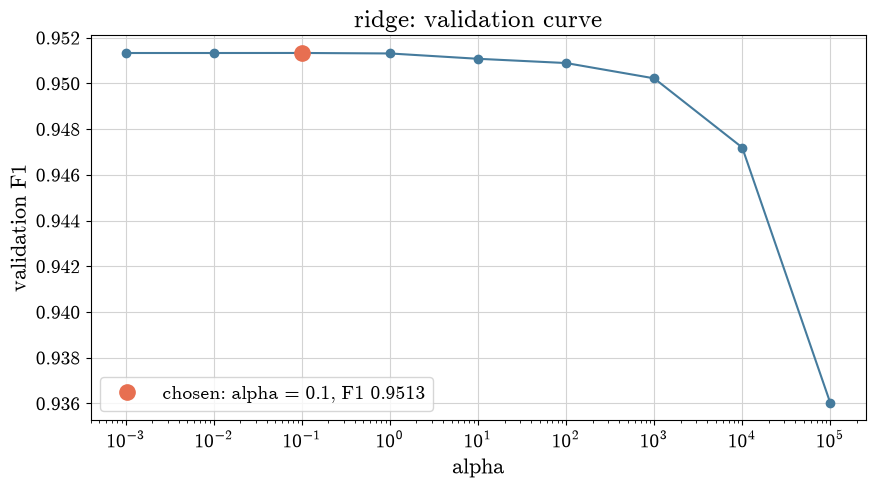

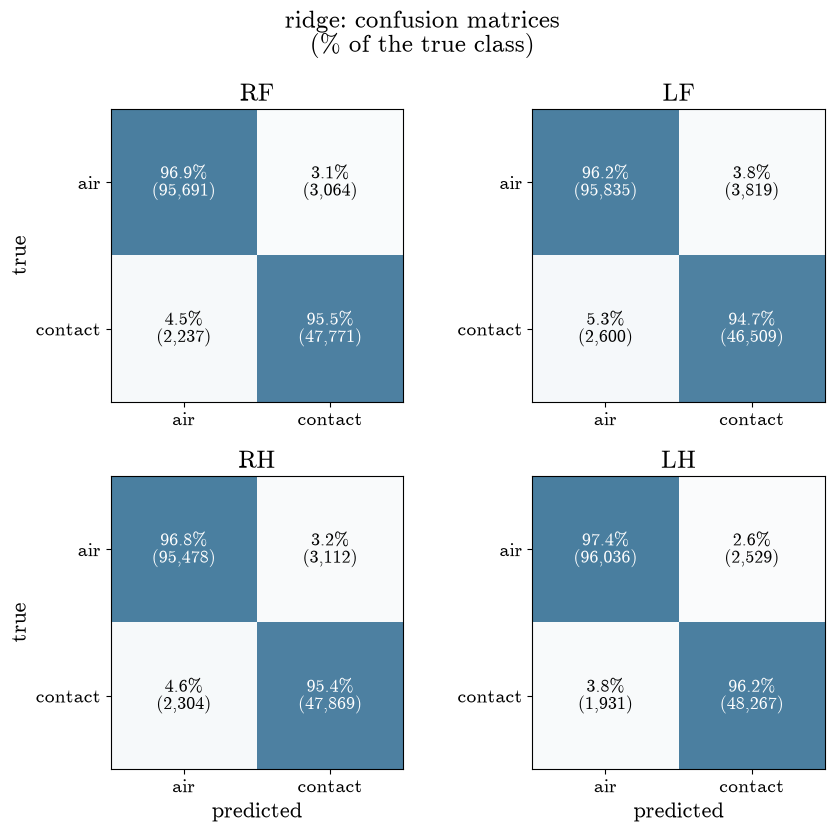

,f1,precision,recall,accuracy
RF,0.9474,0.9397,0.9553,0.9644
LF,0.9354,0.9241,0.9471,0.9569
RH,0.9465,0.9390,0.9541,0.9636
LH,0.9558,0.9502,0.9615,0.9700
mean,0.9463,0.9383,0.9545,0.9637


exact-state accuracy (all 4 legs right): 0.8987


In [26]:
model_card("ridge_feat_all")

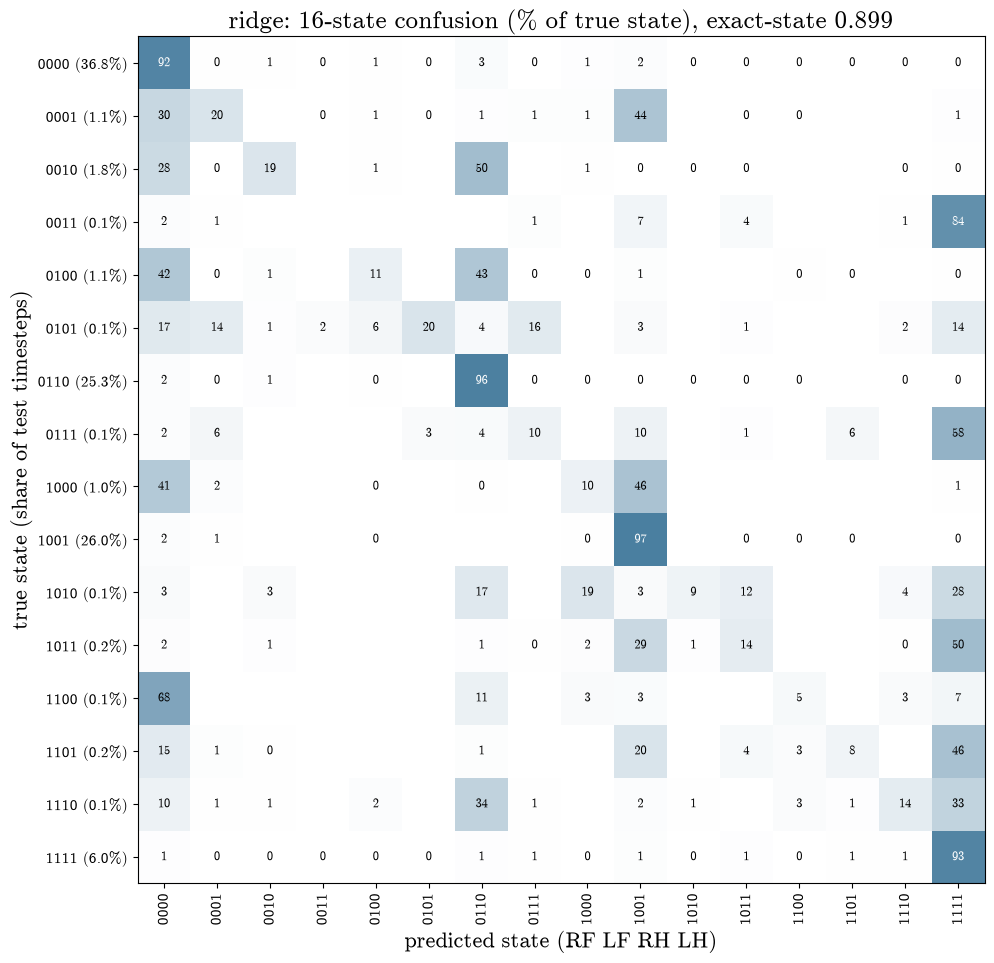

In [27]:
state_confusion("ridge_feat_all")

- α flat again (best 0.1).
- Recall (0.955) > precision (0.938) because recall rose, not because false contacts increased (section 2.3).
- LF still the hardest leg (0.935); galloping (0.83) the hardest recording.

### 7.4 Kernel ridge, RBF (`krr`, `feat_all`)

Standardized features → kernel ridge with RBF kernel k(x, x′) = exp(−γ‖x − x′‖²) on targets ±1 (one output per
leg), contact if the output > 0 — the same loss and penalty as ridge, non-linear boundary. sklearn's `KernelRidge`
has no bias term: the mean target is subtracted before fitting and added back at prediction, which gives it one
(like ridge's intercept). γ = s / 390 (s = 1 is sklearn's default). Trained on the 10k windows of 4.5.
Grid: α ∈ {0.01, 0.03, 0.1, 0.3, 1} × s ∈ {0.1, 0.2, 0.3, 0.5, 1, 2, 3} (35 combinations, ~15 min on a PC).

findfont: Failed to find font weight bold for cmr10, now using 400.


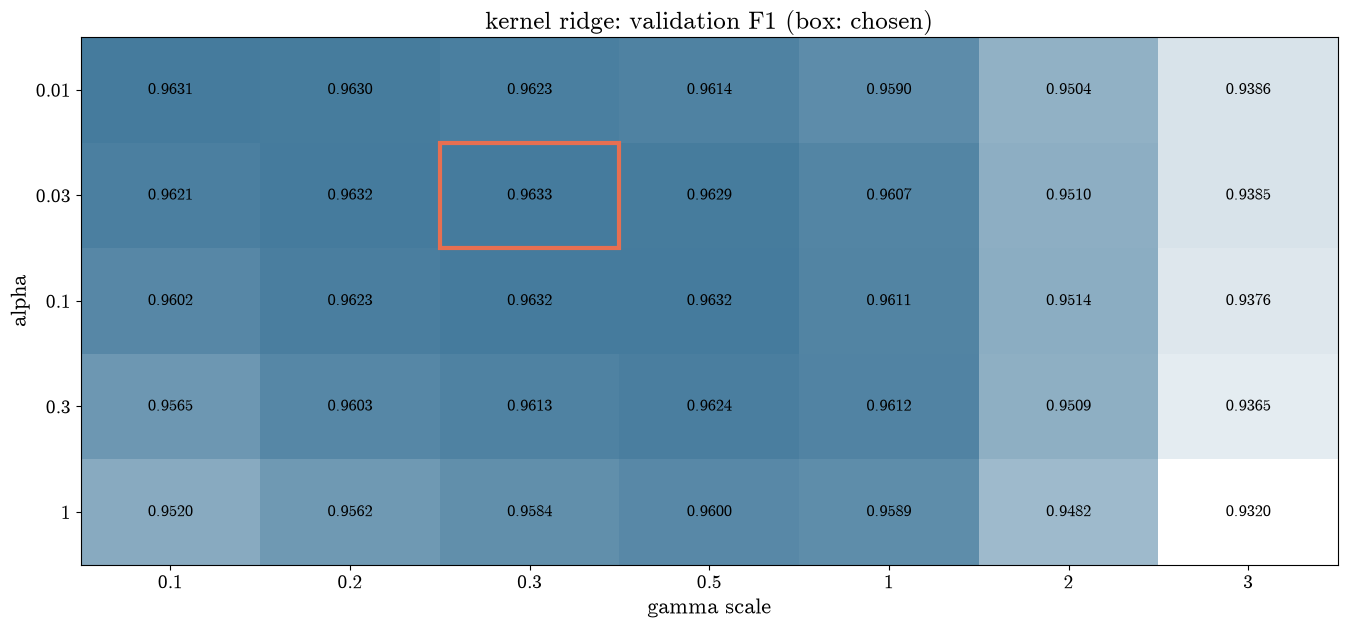

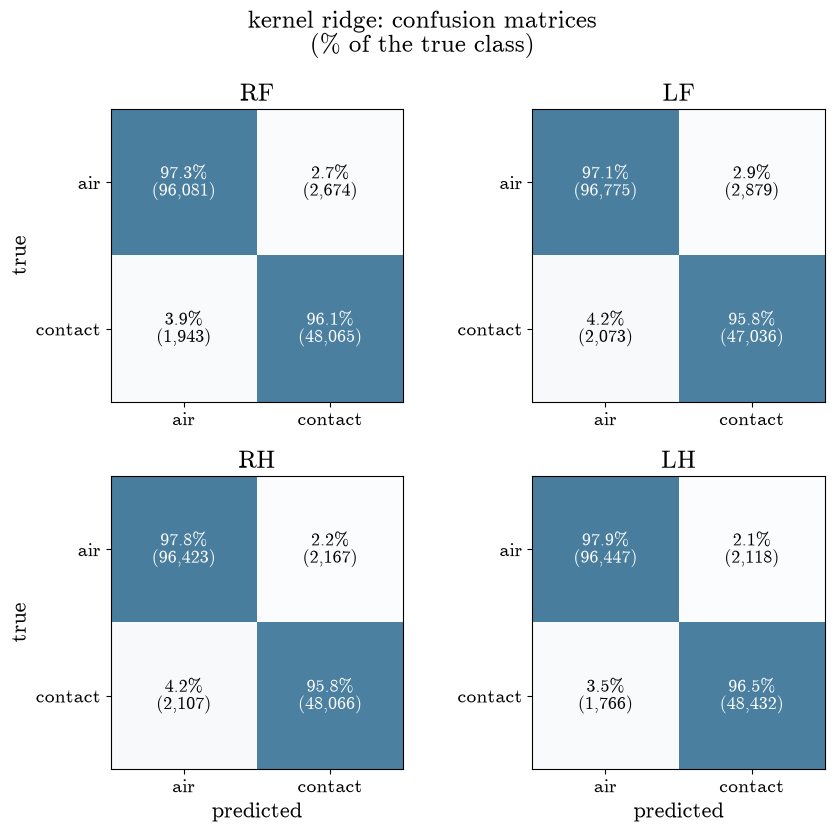

,f1,precision,recall,accuracy
RF,0.9542,0.9473,0.9611,0.9690
LF,0.9500,0.9423,0.9578,0.9667
RH,0.9574,0.9569,0.9580,0.9713
LH,0.9614,0.9581,0.9648,0.9739
mean,0.9558,0.9511,0.9604,0.9702


exact-state accuracy (all 4 legs right): 0.9091


In [28]:
model_card("krr_feat_all")

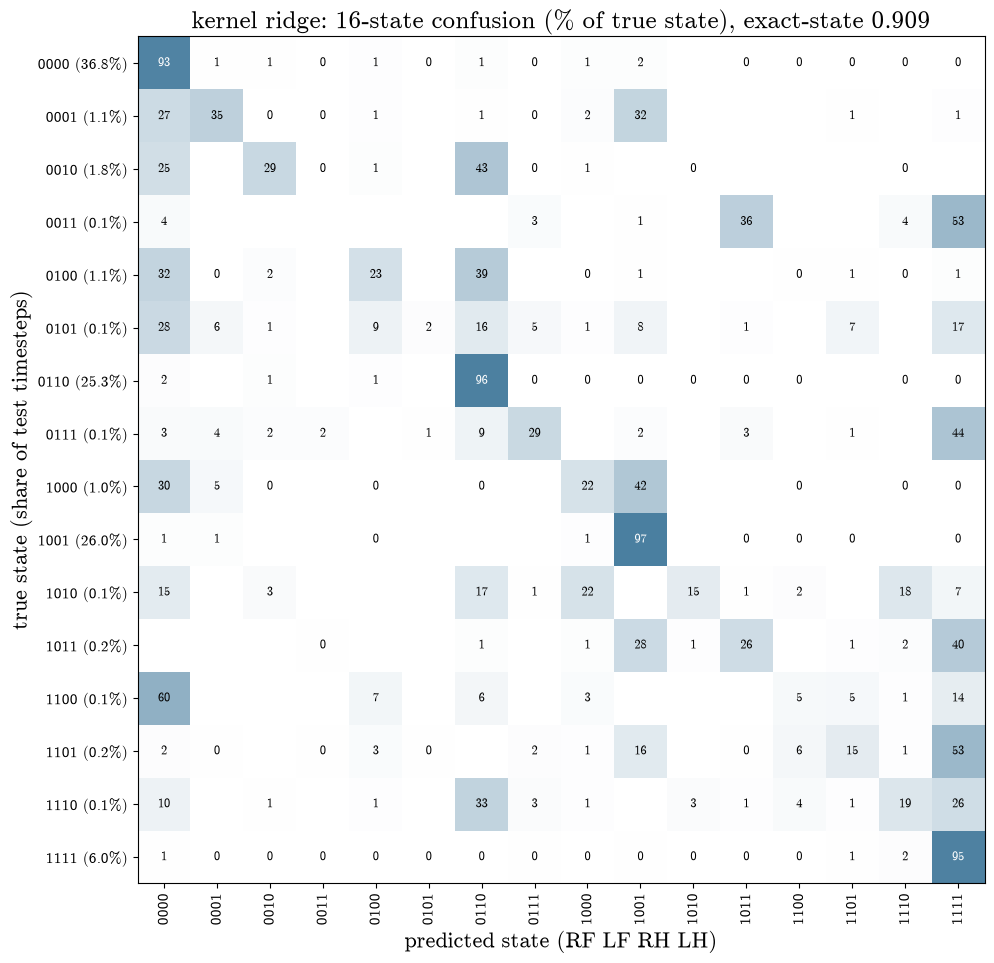

In [29]:
state_confusion("krr_feat_all")

- **Flat optimum along a diagonal band**: a smaller α (less regularization) pairs with a smaller γ (smoother
  kernel). About ten combinations score within 0.001 of the best (0.9633 at α = 0.03, s = 0.3, inside the grid).
- **Performance does not hinge on tuning.** On a flat plateau, which point wins on validation is mostly chance
  (the "winner's curse" of selection), so validation differences below ~0.1 point are not real differences.
- **Large γ is clearly worse** (s ≥ 2 at every α): the kernel becomes too local (each training window only "sees"
  its very near neighbours) — with 10k windows in 390 dimensions it no longer generalizes.
- α and γ **interact**, as in the EMG project — they have to be searched together, not one at a time.
- Precision 0.951 / recall 0.960; LF still the hardest leg (0.950), but the gap to the other legs is smaller.

### 7.5 Decision tree (`tree`, `feat_all`, 70k windows)

One `DecisionTreeClassifier` per leg on the unscaled features. Each split asks "feature j ≤ t?", choosing the feature
and threshold that most reduce the Gini impurity of the two children; each leaf predicts its majority label. Grown
until the leaves are pure or reach `min_samples_leaf` windows.
Grid: `min_samples_leaf` ∈ {1, 5, 20, 50, 100, 200}.

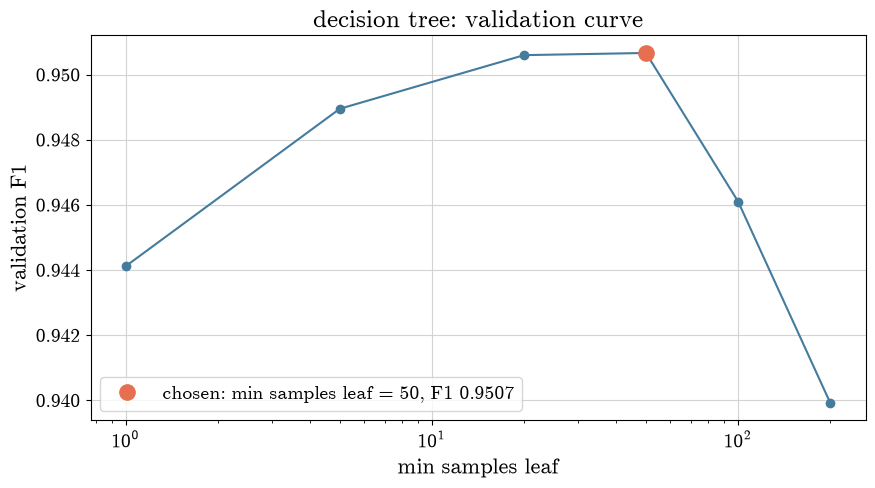

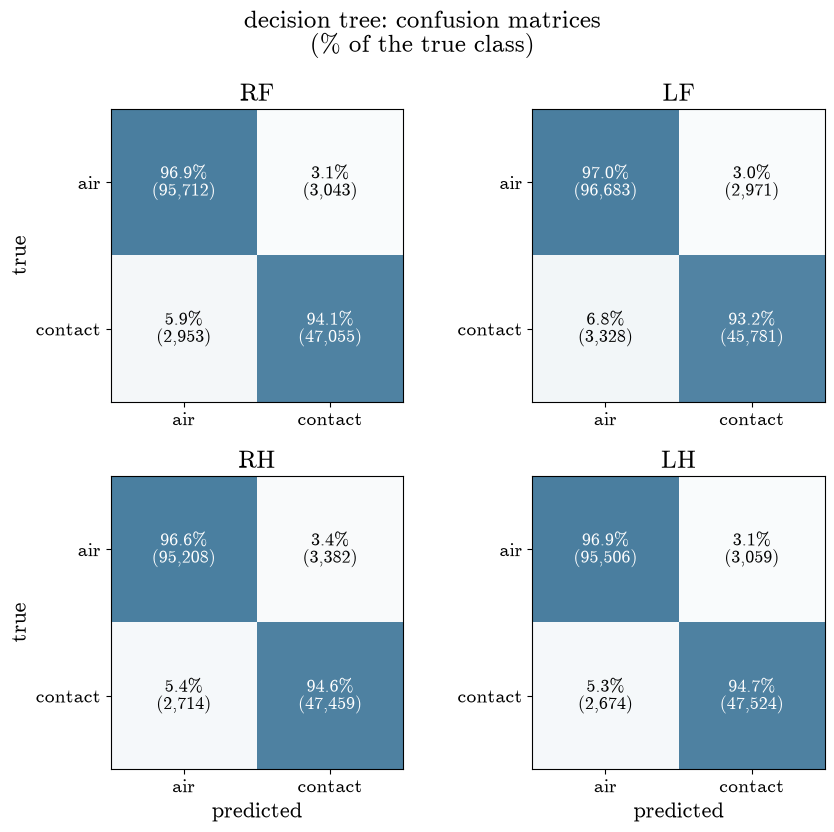

,f1,precision,recall,accuracy
RF,0.9401,0.9393,0.9409,0.9597
LF,0.9356,0.9391,0.9322,0.9577
RH,0.9397,0.9335,0.9459,0.9590
LH,0.9431,0.9395,0.9467,0.9615
mean,0.9396,0.9378,0.9415,0.9595


exact-state accuracy (all 4 legs right): 0.8760


In [30]:
model_card("tree_feat_all")

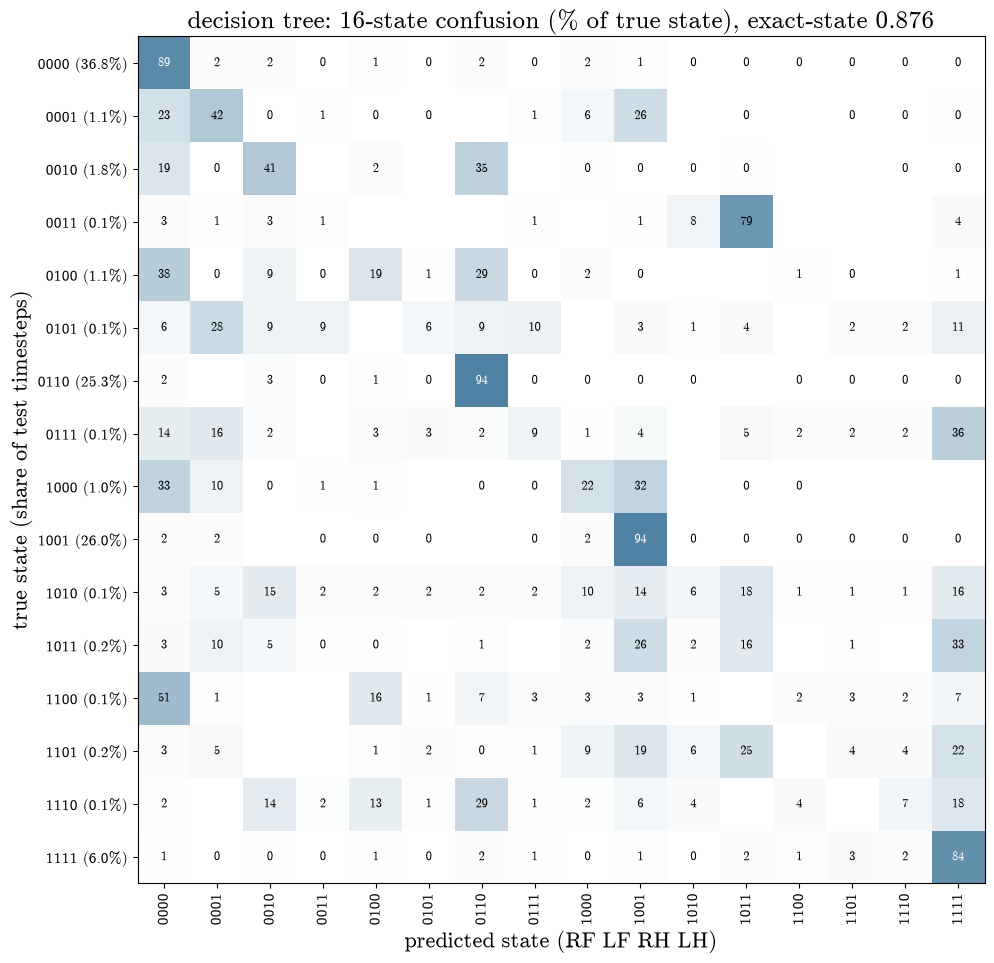

In [31]:
state_confusion("tree_feat_all")

In [32]:
trees_ = joblib.load("../outputs/models/tree_feat_all.joblib").estimators_
pd.DataFrame({leg: {"depth": t.get_depth(), "leaves": t.get_n_leaves()} for leg, t in zip(LEGS, trees_)}).T

,depth,leaves
RF,28,233
LF,29,238
RH,28,232
LH,33,220


- **Leaf size is the bias–variance knob**: 1 window per leaf → 0.944 (memorises near-duplicate windows); 20–50 →
  flat top at 0.951; 200 → 0.940 (leaves too coarse). Chosen 50.
- Final trees: depth 28–33, 220–238 leaves per leg.
- Precision 0.938 / recall 0.942; LF the hardest leg (0.936).

### 7.6 Random forest (`rf`, `feat_all`, 70k windows)

200 `DecisionTreeClassifier`s per leg, each grown on a **bootstrap sample** of the training windows (drawn with
replacement, same size) and choosing each split among a **random subset of `max_features` features**; prediction =
average of the trees' contact probabilities, contact if > 0.5. Both sources of randomness make the trees different,
so their errors partly cancel in the average. The number of trees is fixed (more never hurts, it only costs time).
The out-of-bag score is not used: a window left out of a bootstrap has near-identical neighbours inside it.
Grid: `max_features` ∈ {√390 → 19, 10% → 39, 20% → 78} × `min_samples_leaf` ∈ {1, 5, 20}
(the plot shows `max_features` as a fraction of the 390 features).

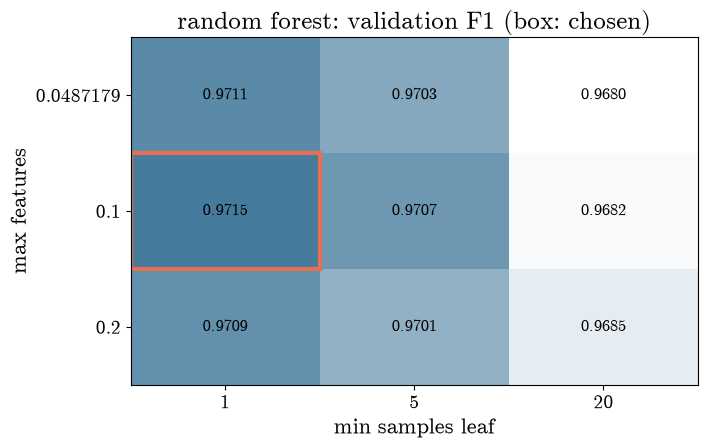

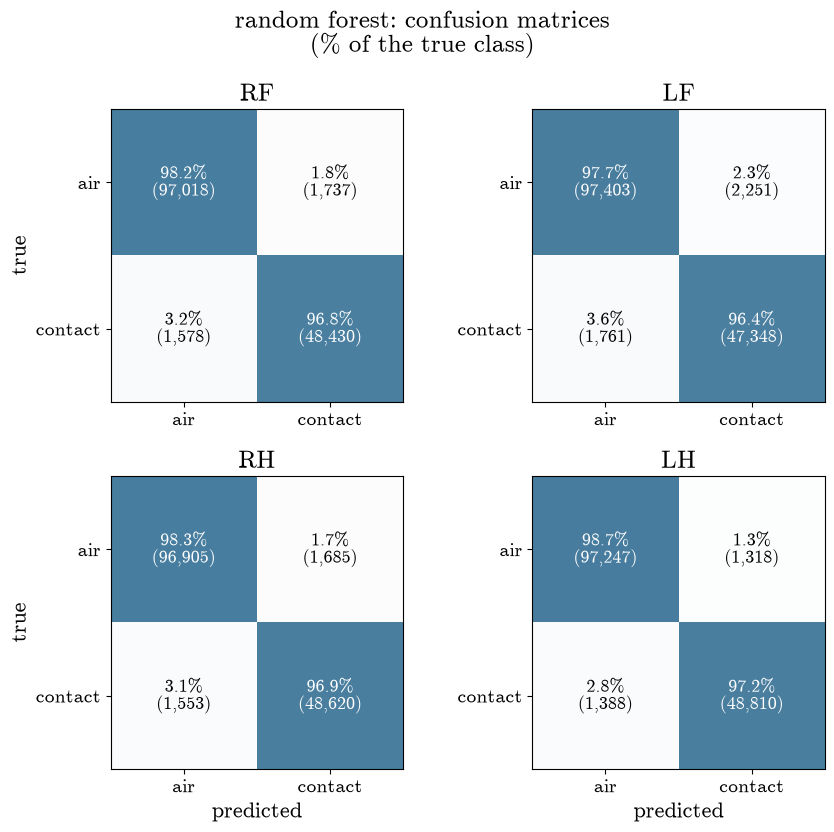

,f1,precision,recall,accuracy
RF,0.9669,0.9654,0.9684,0.9777
LF,0.9594,0.9546,0.9641,0.9730
RH,0.9678,0.9665,0.9690,0.9782
LH,0.9730,0.9737,0.9723,0.9818
mean,0.9668,0.9651,0.9685,0.9777


exact-state accuracy (all 4 legs right): 0.9278


In [33]:
model_card("rf_feat_all")

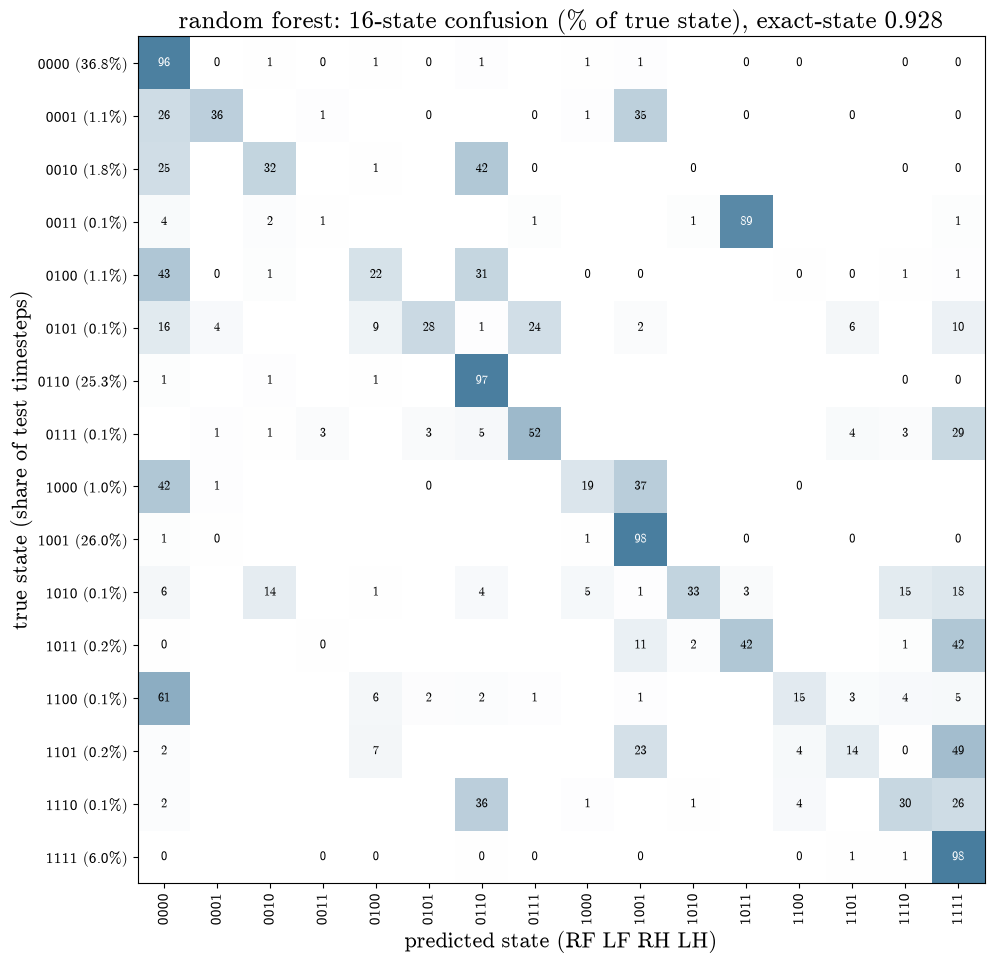

In [34]:
state_confusion("rf_feat_all")

In [35]:
forest = joblib.load("../outputs/models/rf_feat_all.joblib").estimators_
pd.DataFrame({leg: {"mean depth": np.mean([t.get_depth() for t in f.estimators_]),
                    "mean leaves": np.mean([t.get_n_leaves() for t in f.estimators_])}
              for leg, f in zip(LEGS, forest)}).T.round(0)

,mean depth,mean leaves
RF,39.0,1048.0
LF,38.0,1136.0
RH,38.0,1050.0
LH,38.0,989.0


- **The smallest leaves are best** (`min_samples_leaf` = 1 at every `max_features`) — the opposite of the single tree,
  where 1 window per leaf was clearly worse (0.944 vs 0.951). Each deep tree memorises, but averaging 200 different
  ones cancels most of it: variance is exactly what the forest removes. (1 is the grid's edge, but cannot go lower.)
- **`max_features` barely matters** (0.9709–0.9715 at leaf size 1); chosen 39 features per split (0.9715). The whole
  grid lies within 0.968–0.9715.
- Trees: depth ~38, ~990–1,140 leaves per tree — 4–5× the leaves of the tuned single tree. 800 trees in total
  (135 MB file).
- Precision 0.965 / recall 0.968; LF the hardest leg (0.959). Validation → test gap 0.5 points (0.9715 → 0.967).

### 7.7 Gradient boosting (`gb`, `feat_all`, 70k windows)

One `HistGradientBoostingClassifier` per leg: F(x) = Σₘ ν·hₘ(x), p(contact) = σ(F(x)), contact if p > 0.5. Each new
tree hₘ is fitted to the gradient of the log-loss of the current ensemble (for this loss: the residual y − p, what
the model still gets wrong), scaled by the learning rate ν = 0.1. Features are binned into 255 quantile bins, which
makes each split fast at 70k × 390. Early stopping off (it would hold out a random 10% of near-duplicate windows).
Grid: `max_iter` (number of trees) ∈ {100, 200, 400, 800} × `max_leaf_nodes` (tree size) ∈ {15, 31, 63, 127};
ν fixed, since it trades off against the number of trees.

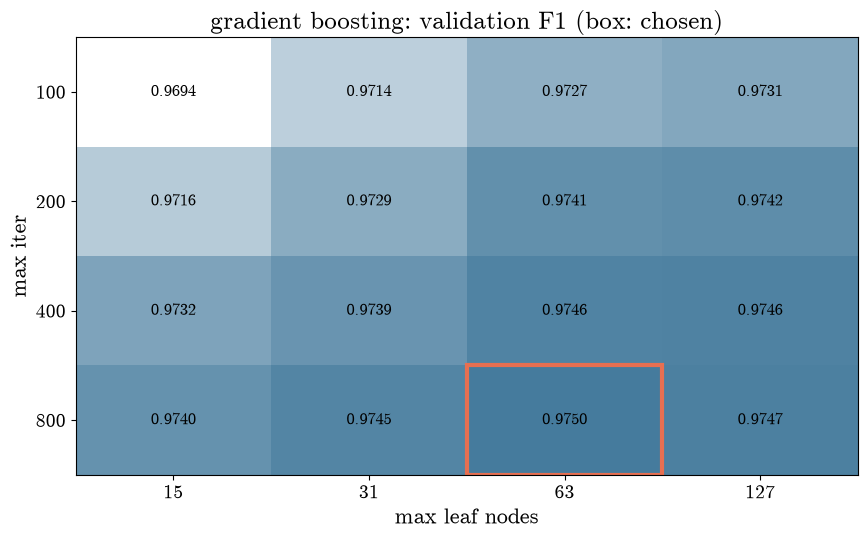

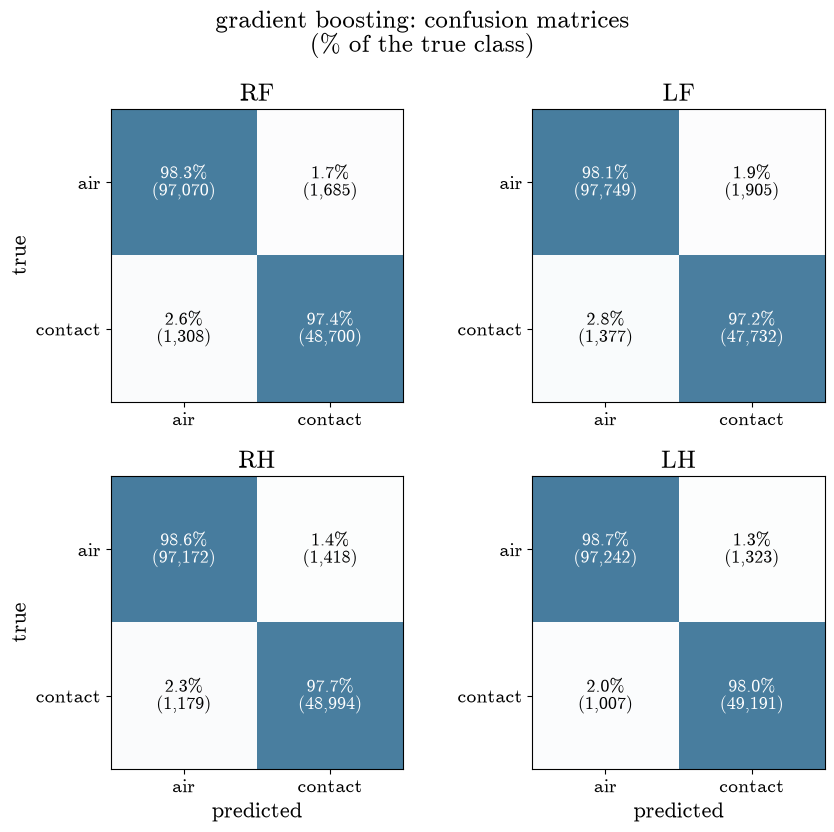

,f1,precision,recall,accuracy
RF,0.9702,0.9666,0.9738,0.9799
LF,0.9668,0.9616,0.9720,0.9779
RH,0.9742,0.9719,0.9765,0.9825
LH,0.9769,0.9738,0.9799,0.9843
mean,0.9720,0.9685,0.9756,0.9812


exact-state accuracy (all 4 legs right): 0.9368


In [36]:
model_card("gb_feat_all")

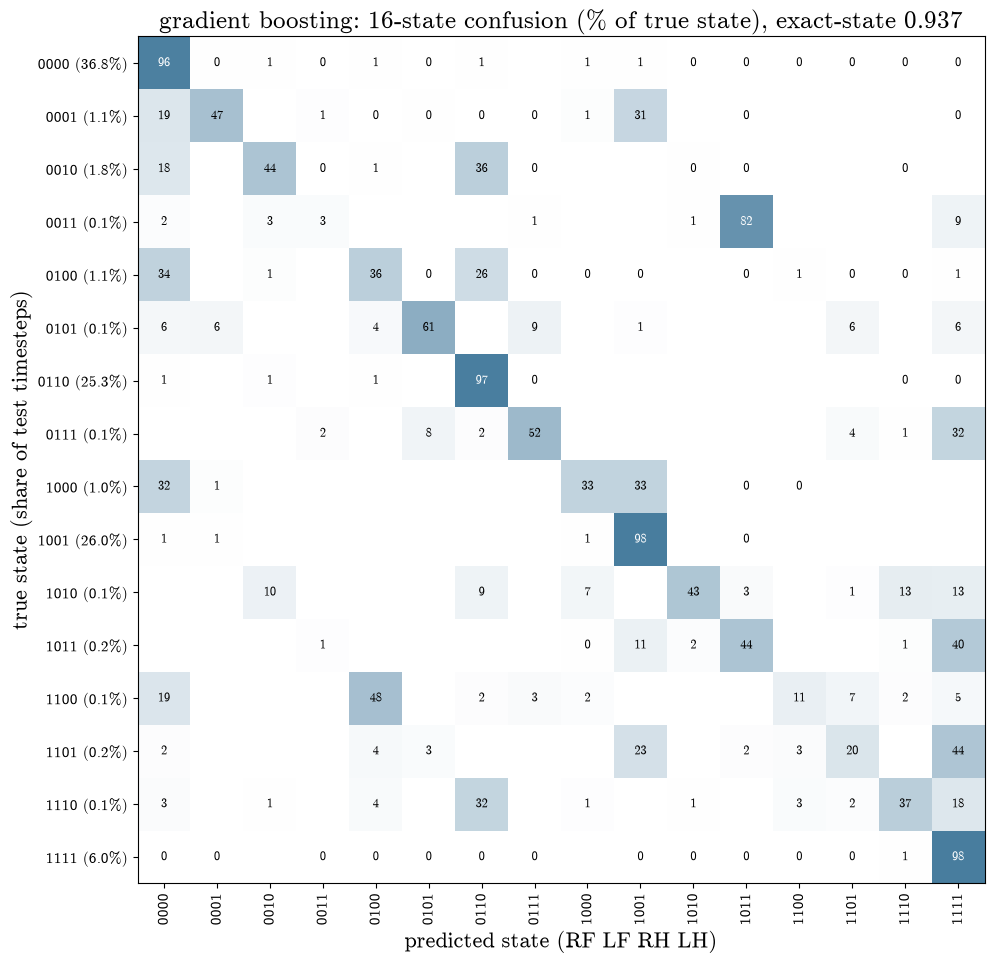

In [37]:
state_confusion("gb_feat_all")

- **The whole grid lies between 0.969 and 0.975**: even the smallest model (100 trees × 15 leaves, 0.9694) beats every
  other model on validation (kernel ridge 0.963) — performance does not hinge on tuning.
- **More and bigger trees both help, with diminishing returns**: chosen 800 trees × 63 leaves (0.9750); 127 leaves
  changes nothing (±0.0004). The choice is on the upper edge of `max_iter`, but each doubling adds less (at 63 leaves: +0.14,
  +0.05, +0.04 points), already below the ~0.1-point noise of validation. Checked beyond the edge (validation only, one train-only fit
  scored after every tree up to 3,200): 0.9754 at 1,200 trees, then flat at 0.9753 (127 leaves: flat at 0.9748) —
  +0.04 points at most, so 800 stays.
- Precision 0.969 / recall 0.976; false contacts 1.3–1.9% per leg; LF still the hardest leg (0.967), but close.
- Validation → test gap 0.3 points (0.975 → 0.972), the smallest of all models.

### 7.8 Gradient boosting on 10k windows (`gb_10k`, `feat_all`)

The boosting of 4.12 (same grid) trained on the kernel methods' 10k windows (evenly spaced in time) — the equal-data reference for kernel ridge.

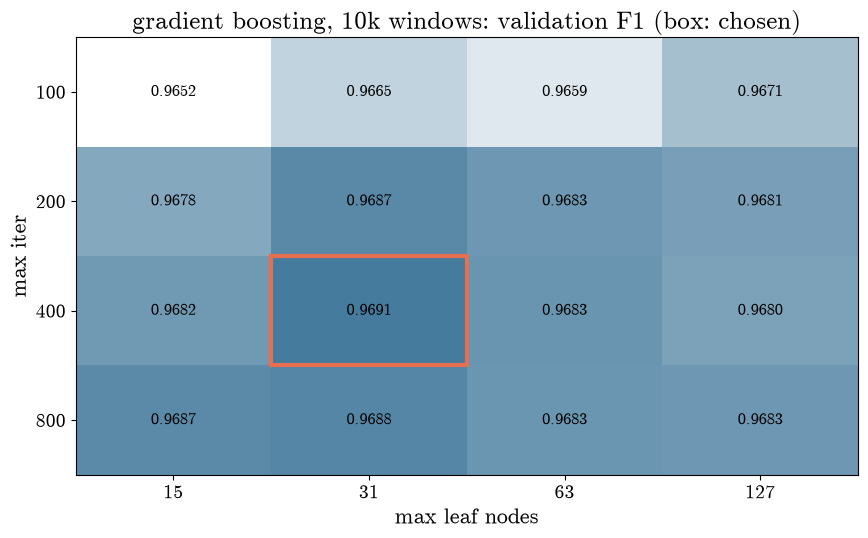

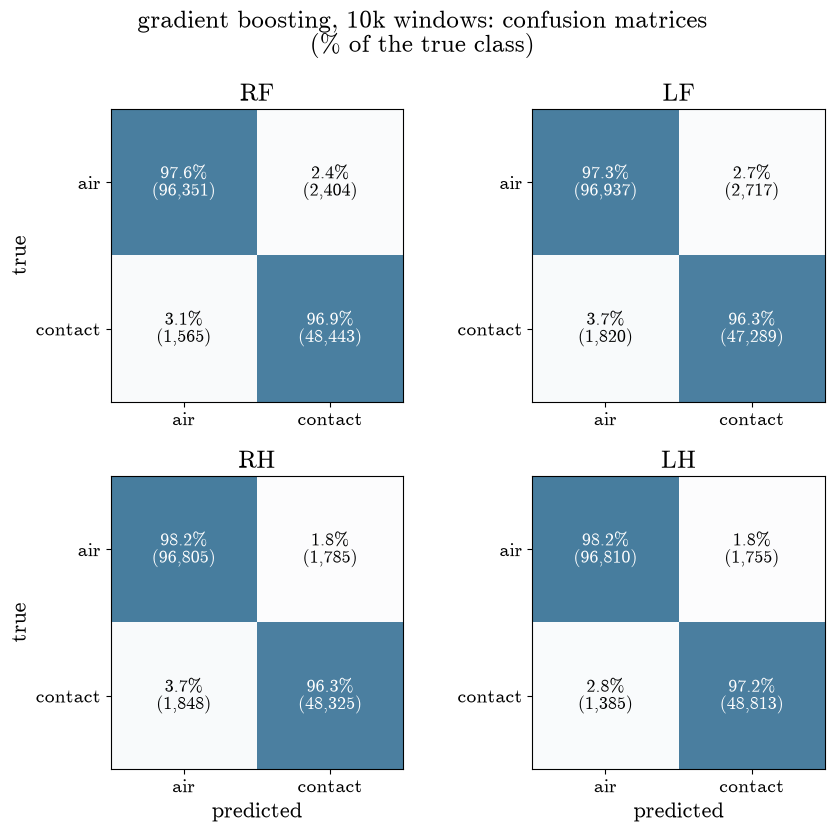

,f1,precision,recall,accuracy
RF,0.9606,0.9527,0.9687,0.9733
LF,0.9542,0.9457,0.9629,0.9695
RH,0.9638,0.9644,0.9632,0.9756
LH,0.9688,0.9653,0.9724,0.9789
mean,0.9619,0.9570,0.9668,0.9743


exact-state accuracy (all 4 legs right): 0.9179


In [38]:
model_card("gb_10k_feat_all")

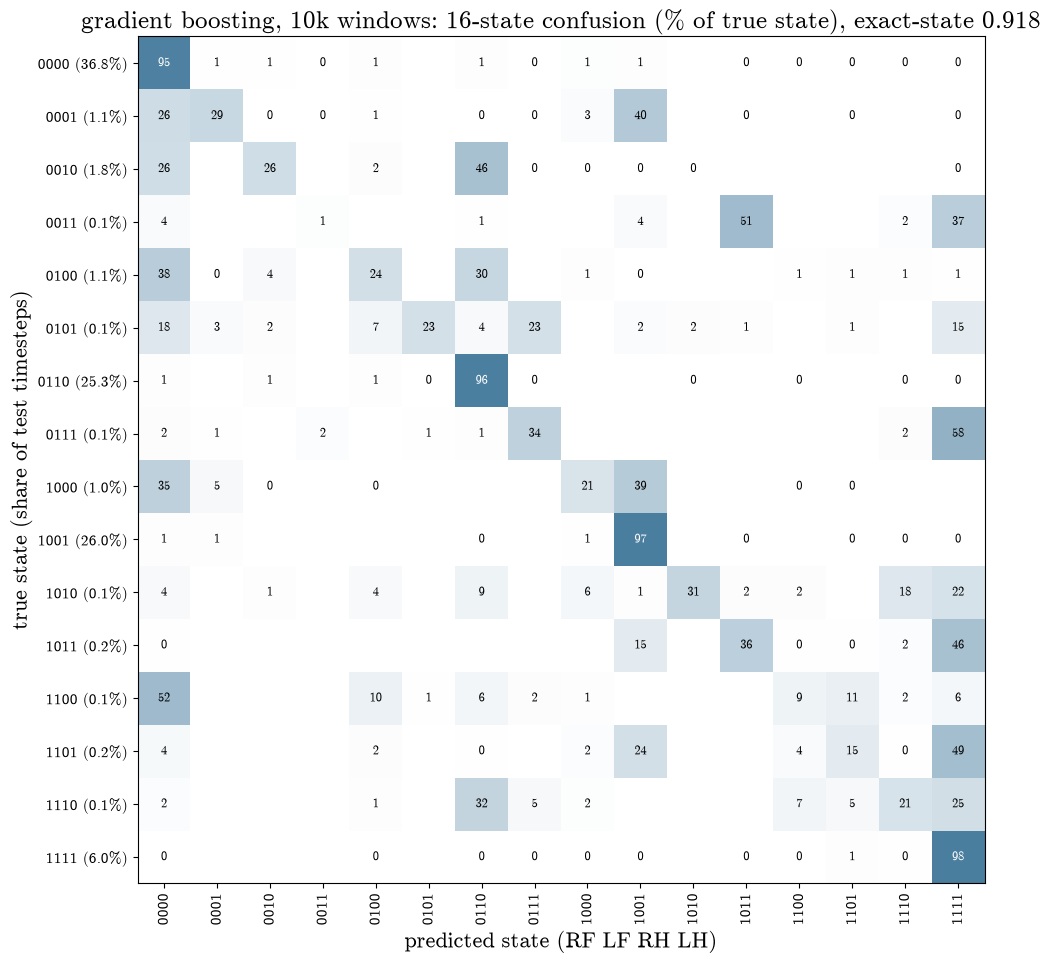

In [39]:
state_confusion("gb_10k_feat_all")

- **Best 400 trees × 31 leaves (0.9691), inside the grid**; the whole grid within 0.965–0.969. With 7× fewer windows,
  bigger trees no longer help (127 leaves ≤ 31 from 200 trees on): there is less to learn before over-fitting.
- Validation → test gap 0.7 points (0.969 → 0.962), like kernel ridge on the same windows (0.963 → 0.956).
- Precision 0.957 / recall 0.967; LF the hardest leg (0.954).